(sec-5)=
# 5. Benchmark de los modelos base y definición del baseline

En esta sección se comparan los tres modelos, se fija el baseline y se calcula el margen de mejora que debe superar un modelo avanzado, con pruebas de hipótesis formales. El orden es el siguiente: primero la tabla comparativa y el ranking, luego la definición del baseline y del umbral, después la verificación de supuestos y, finalmente, las pruebas. El nivel de significancia es α = 0,05, declarado en la sección 1 antes de ver cualquier resultado. Las observaciones pareadas son las semillas, que comparten partición y conjunto de prueba en los tres modelos.

(sec-5-1)=
## 5.1 Comparación tabular

In [31]:
def intervalo_t(valores):
    valores = np.asarray(valores, dtype=float)
    medio = stats.t.ppf(0.975, len(valores) - 1) * valores.std(ddof=1) / np.sqrt(len(valores))
    return valores.mean() - medio, valores.mean() + medio


if hay_resultados:
    filas_tabla = []
    for nombre in NOMBRES:
        g = METRICAS[METRICAS["Modelo"] == nombre]
        fila = {"Modelo": nombre}
        for metrica in ["F1 macro", "Accuracy", "Balanced accuracy", "Precision macro", "Recall macro", "F1 ponderado", "Precision ponderada", "Recall ponderado", "AUC-ROC macro", "AUC-PR macro", "MCC", "ECE"]:
            a, b = intervalo_t(g[metrica])
            fila[metrica] = f"{num(g[metrica].mean(), 4)} ± {num(g[metrica].std(ddof=1), 4)} [{num(a, 4)}; {num(b, 4)}]"
        fila["Parámetros"] = num(g["Parámetros"].iloc[0], 0)
        fila["Minutos de entrenamiento"] = f"{num(g['Minutos'].mean(), 1)} ± {num(g['Minutos'].std(ddof=1), 1)}"
        fila["ms por muestra"] = num(g["ms por muestra"].mean(), 3)
        filas_tabla.append(fila)
    tabla_benchmark = pd.DataFrame(filas_tabla).set_index("Modelo").T
    display(tabla_benchmark)
    tabla_benchmark.to_csv(RESULTADOS / "tabla_benchmark.csv")
    medias_f1 = MATRIZ_F1.mean()
    desv_f1 = MATRIZ_F1.std(ddof=1)
    medias_auc = METRICAS.groupby("Modelo")[["AUC-ROC macro", "AUC-PR macro", "ECE"]].mean()
    mejor_auc = medias_auc["AUC-ROC macro"].idxmax()
    interpretar(f'''**Interpretación.** La tabla reporta media ± desviación estándar sobre {len(SEMILLAS)} semillas y, entre corchetes, el intervalo de confianza al 95 % calculado con la $t$ de Student, $\\bar{{x}} \\pm t_{{0,975;\\,n-1}}\\, s / \\sqrt{{n}}$. En la métrica primaria, {NOMBRES[0]} obtiene {num(medias_f1[NOMBRES[0]], 4)}, {NOMBRES[1]} {num(medias_f1[NOMBRES[1]], 4)} y {NOMBRES[2]} {num(medias_f1[NOMBRES[2]], 4)}, con desviaciones entre semillas de {num(desv_f1.min(), 4)} a {num(desv_f1.max(), 4)}. {"" if mejor_auc == NOMBRES[0] else f"El orden cambia con la métrica: {mejor_auc} obtiene el mayor AUC-ROC macro, {num(medias_auc.loc[mejor_auc, 'AUC-ROC macro'], 4)}, y su AUC-PR macro es de {num(medias_auc.loc[mejor_auc, 'AUC-PR macro'], 4)}, con un ECE de {num(medias_auc.loc[mejor_auc, 'ECE'], 4)}."}

Hay que tener en cuenta que esa dispersión mide la inicialización y el orden de los lotes, no la selección de los datos, porque todas las corridas comparten la partición. Por eso los intervalos no deben leerse como la incertidumbre total de generalización, que se aborda con el remuestreo por bloques y con la validación cruzada repetida en la sección 5.4.

Por tal motivo, se opta por usar esta tabla para describir el desempeño y por apoyar toda afirmación comparativa en las pruebas pareadas de la sección 5.4, no en los promedios.''')

Modelo,CNN 1D,DNN,LSTM
F1 macro,"0,8549 ± 0,0091 [0,8466; 0,8633]","0,8548 ± 0,0110 [0,8446; 0,8649]","0,8423 ± 0,0135 [0,8298; 0,8547]"
Accuracy,"0,8607 ± 0,0088 [0,8526; 0,8689]","0,8604 ± 0,0111 [0,8502; 0,8707]","0,8499 ± 0,0134 [0,8375; 0,8623]"
Balanced accuracy,"0,8636 ± 0,0081 [0,8562; 0,8711]","0,8617 ± 0,0113 [0,8513; 0,8722]","0,8501 ± 0,0119 [0,8391; 0,8610]"
Precision macro,"0,8561 ± 0,0078 [0,8489; 0,8633]","0,8545 ± 0,0118 [0,8437; 0,8654]","0,8438 ± 0,0172 [0,8279; 0,8597]"
Recall macro,"0,8636 ± 0,0081 [0,8562; 0,8711]","0,8617 ± 0,0113 [0,8513; 0,8722]","0,8501 ± 0,0119 [0,8391; 0,8610]"
F1 ponderado,"0,8619 ± 0,0086 [0,8540; 0,8698]","0,8610 ± 0,0111 [0,8507; 0,8712]","0,8503 ± 0,0133 [0,8380; 0,8626]"
Precision ponderada,"0,8711 ± 0,0076 [0,8641; 0,8782]","0,8672 ± 0,0120 [0,8561; 0,8783]","0,8587 ± 0,0160 [0,8439; 0,8735]"
Recall ponderado,"0,8607 ± 0,0088 [0,8526; 0,8689]","0,8604 ± 0,0111 [0,8502; 0,8707]","0,8499 ± 0,0134 [0,8375; 0,8623]"
AUC-ROC macro,"0,9637 ± 0,0010 [0,9627; 0,9646]","0,9602 ± 0,0050 [0,9556; 0,9648]","0,9728 ± 0,0048 [0,9684; 0,9773]"
AUC-PR macro,"0,8511 ± 0,0066 [0,8450; 0,8571]","0,8336 ± 0,0104 [0,8239; 0,8432]","0,8791 ± 0,0235 [0,8574; 0,9008]"


**Interpretación.** La tabla reporta media ± desviación estándar sobre 7 semillas y, entre corchetes, el intervalo de confianza al 95 % calculado con la $t$ de Student, $\bar{x} \pm t_{0,975;\,n-1}\, s / \sqrt{n}$. En la métrica primaria, CNN 1D obtiene 0,8549, DNN 0,8548 y LSTM 0,8423, con desviaciones entre semillas de 0,0091 a 0,0135. El orden cambia con la métrica: LSTM obtiene el mayor AUC-ROC macro, 0,9728, y su AUC-PR macro es de 0,8791, con un ECE de 0,0402.

Hay que tener en cuenta que esa dispersión mide la inicialización y el orden de los lotes, no la selección de los datos, porque todas las corridas comparten la partición. Por eso los intervalos no deben leerse como la incertidumbre total de generalización, que se aborda con el remuestreo por bloques y con la validación cruzada repetida en la sección {ref}`5.4 <sec-5-4>`.

Por tal motivo, se opta por usar esta tabla para describir el desempeño y por apoyar toda afirmación comparativa en las pruebas pareadas de la sección {ref}`5.4 <sec-5-4>`, no en los promedios.

(sec-5-2)=
## 5.2 Ranking de los modelos base

Se ordenan los tres modelos por la métrica primaria y se contrasta ese orden con su costo: número de parámetros, tiempo de entrenamiento y tiempo de inferencia. El propósito es determinar si la mayor complejidad se traduce en mejor desempeño.

,Posición,F1 macro,Parámetros (M),Minutos,ms por muestra
Modelo,,,,,
CNN 1D,1,"0,8549","0,0395","1,4674","0,0287"
DNN,2,"0,8548","0,0127","0,6455","0,0007"
LSTM,3,"0,8423","0,0175","2,299","0,01"


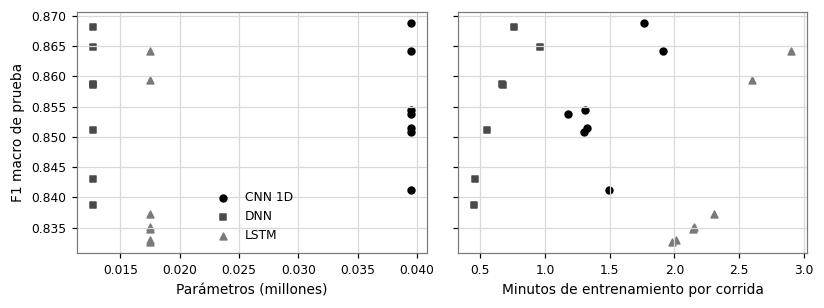

**Interpretación.** El orden por F1 macro es CNN 1D, DNN, LSTM. El modelo con más parámetros es CNN 1D, con 0,04 millones, y el más lento de entrenar es LSTM, con 2,3 minutos por corrida. El mejor modelo es también el más grande, aunque supera a DNN por solo 0,0002. Frente a DNN, CNN 1D usa 3,1 veces los parámetros, 2,3 veces el tiempo de entrenamiento y 41 veces el tiempo de inferencia por muestra.

Lo anterior indica que, entre estos tres modelos, más parámetros no se traducen de forma directa en mejor desempeño: LSTM tiene más parámetros que DNN y un F1 macro menor. Sin embargo, con tres modelos esa relación es solo una descripción, porque no hay grados de libertad para estimarla, y además mezcla capacidad con sesgo inductivo.

Por ello, se recomienda leer el *trade-off* junto con la significancia y la relevancia práctica de la sección {ref}`5.4 <sec-5-4>`: una diferencia pequeña no justifica por sí sola el costo de un modelo mayor.

In [32]:
if hay_resultados:
    ranking = METRICAS.groupby("Modelo").agg(**{"F1 macro": ("F1 macro", "mean"), "Parámetros (M)": ("Parámetros", lambda v: v.iloc[0] / 1e6), "Minutos": ("Minutos", "mean"), "ms por muestra": ("ms por muestra", "mean")}).loc[NOMBRES]
    ranking.insert(0, "Posición", range(1, len(ranking) + 1))
    display(ranking.round(4))
    fig, ejes = plt.subplots(1, 2, figsize=(7.6, 2.9), sharey=True)
    for nombre, estilo in zip(NOMBRES, ESTILOS):
        g = METRICAS[METRICAS["Modelo"] == nombre]
        ejes[0].scatter(g["Parámetros"] / 1e6, g["F1 macro"], color=estilo["color"], marker=estilo["marker"], s=20, label=nombre)
        ejes[1].scatter(g["Minutos"], g["F1 macro"], color=estilo["color"], marker=estilo["marker"], s=20)
    ejes[0].set(xlabel="Parámetros (millones)", ylabel="F1 macro de prueba")
    ejes[1].set(xlabel="Minutos de entrenamiento por corrida")
    ejes[0].legend(frameon=False)
    plt.tight_layout()
    plt.show()
    mas_grande = ranking["Parámetros (M)"].idxmax()
    mas_lento = ranking["Minutos"].idxmax()
    contraejemplo = next(((a, b) for a in NOMBRES for b in NOMBRES if ranking.loc[a, "Parámetros (M)"] > ranking.loc[b, "Parámetros (M)"] and ranking.loc[a, "F1 macro"] < ranking.loc[b, "F1 macro"]), None)
    interpretar(f'''**Interpretación.** El orden por F1 macro es {", ".join(NOMBRES)}. El modelo con más parámetros es {mas_grande}, con {num(ranking.loc[mas_grande, "Parámetros (M)"], 2)} millones, y el más lento de entrenar es {mas_lento}, con {num(ranking.loc[mas_lento, "Minutos"], 1)} minutos por corrida. {f"El mejor modelo es también el más grande, aunque supera a {NOMBRES[1]} por solo {num(ranking.loc[NOMBRES[0], 'F1 macro'] - ranking.loc[NOMBRES[1], 'F1 macro'], 4)}." if NOMBRES[0] == mas_grande else f"El mejor modelo no es el más grande: {NOMBRES[0]} tiene {num(ranking.loc[NOMBRES[0], 'Parámetros (M)'], 2)} millones."} Frente a {NOMBRES[1]}, {NOMBRES[0]} usa {num(ranking.loc[NOMBRES[0], "Parámetros (M)"] / ranking.loc[NOMBRES[1], "Parámetros (M)"], 1)} veces los parámetros, {num(ranking.loc[NOMBRES[0], "Minutos"] / ranking.loc[NOMBRES[1], "Minutos"], 1)} veces el tiempo de entrenamiento y {num(ranking.loc[NOMBRES[0], "ms por muestra"] / ranking.loc[NOMBRES[1], "ms por muestra"], 0)} veces el tiempo de inferencia por muestra.

Lo anterior indica {"que, entre estos tres modelos, más parámetros se acompañan de mejor desempeño" if contraejemplo is None else f"que, entre estos tres modelos, más parámetros no se traducen de forma directa en mejor desempeño: {contraejemplo[0]} tiene más parámetros que {contraejemplo[1]} y un F1 macro menor"}. Sin embargo, con tres modelos esa relación es solo una descripción, porque no hay grados de libertad para estimarla, y además mezcla capacidad con sesgo inductivo.

Por ello, se recomienda leer el *trade-off* junto con la significancia y la relevancia práctica de la sección 5.4: una diferencia pequeña no justifica por sí sola el costo de un modelo mayor.''')

(sec-5-3)=
## 5.3 Definición del baseline y margen de mejora disponible

Este es el objetivo central del entregable. Se identifica el mejor modelo, se cuantifican las diferencias absolutas y relativas con los demás, con la $d$ de Cohen (1988) como tamaño de efecto, y se define el umbral de mejora. La mejora mínima detectable sale de la potencia exacta de la prueba $t$ pareada con α = 0,05 y potencia de 0,80, y el umbral combina esa cifra con el margen de relevancia δ = 0,01 declarado a priori: $\text{umbral} = \overline{F1}_{\text{baseline}} + \max(\delta, \text{mejora mínima detectable})$.

In [33]:
ALFA, POTENCIA_OBJETIVO, DELTA = 0.05, 0.80, 0.01
# Valores publicados sobre UAVIDS-2025, con partición aleatoria: artículo de Zeng et al. (2025) y Zarkadis y Douligeris (2026)
LITERATURA_F1 = [("DNN, Zeng et al. (2025)", 0.93), ("CNN, Zeng et al. (2025)", 0.93), ("LSTM, Zeng et al. (2025)", 0.94), ("MLP, Zarkadis y Douligeris (2026)", 0.9066), ("RealMLP, Zarkadis y Douligeris (2026)", 0.9428)]


def potencia_pareada(desviacion, n, efecto):
    return TTestPower().power(effect_size=abs(efecto) / desviacion, nobs=n, alpha=ALFA, alternative="two-sided") if desviacion > 0 else 1.0


def minima_detectable(desviacion, n):
    return TTestPower().solve_power(effect_size=None, nobs=n, alpha=ALFA, power=POTENCIA_OBJETIVO, alternative="two-sided") * desviacion


if hay_resultados:
    BASELINE = NOMBRES[0]
    a, b = intervalo_t(MATRIZ_F1[BASELINE])
    diferencias = []
    for nombre in NOMBRES[1:]:
        d = MATRIZ_F1[BASELINE] - MATRIZ_F1[nombre]
        sd = d.std(ddof=1)
        diferencias.append({"Comparación": f"{BASELINE} - {nombre}", "Diferencia absoluta": d.mean(), "Diferencia relativa (%)": 100 * d.mean() / MATRIZ_F1[nombre].mean(), "σ̂_d": sd, "δ/σ̂_d": DELTA / sd if sd > 0 else np.inf,
                            "d de Cohen pareada": d.mean() / sd if sd > 0 else np.inf, "Mínima detectable": minima_detectable(sd, len(d)), "Potencia para δ": potencia_pareada(sd, len(d), DELTA)})
    diferencias = pd.DataFrame(diferencias)
    display(diferencias.round(4))
    # Referencias de contexto, sin Deep Learning, ajustadas solo con entrenamiento y evaluadas una vez en prueba
    logistico_ref = LogisticRegression(C=1.0, max_iter=3000).fit(X[id_ent].numpy(), y_np[particion["entrenamiento"]])
    boosting_ref = HistGradientBoostingClassifier(max_iter=150, random_state=SEMILLA).fit(X[id_ent].numpy(), y_np[particion["entrenamiento"]])
    f1_logistico_ref = f1_score(y_prueba, logistico_ref.predict(X[id_pru].numpy()), average="macro")
    f1_boosting_ref = f1_score(y_prueba, boosting_ref.predict(X[id_pru].numpy()), average="macro")
    filas_referencia = [{"Modelo": f"{n}, este trabajo", "Partición": "Agrupada por bloques", "F1": METRICAS.loc[METRICAS["Modelo"] == n, "F1 macro"].mean(), "Promedio": "Macro"} for n in NOMBRES]
    filas_referencia += [{"Modelo": "Regresión logística, este trabajo (contexto)", "Partición": "Agrupada por bloques", "F1": f1_logistico_ref, "Promedio": "Macro"}, {"Modelo": "Boosting, este trabajo (contexto)", "Partición": "Agrupada por bloques", "F1": f1_boosting_ref, "Promedio": "Macro"}]
    filas_referencia += [{"Modelo": m, "Partición": "Aleatoria estratificada", "F1": v, "Promedio": "Según lo publicado"} for m, v in LITERATURA_F1]
    display(pd.DataFrame(filas_referencia).style.hide(axis="index").format({"F1": "{:.4f}"}))
    sigma_referencia = float(diferencias["σ̂_d"].max())
    MINIMA = minima_detectable(sigma_referencia, len(SEMILLAS))
    UMBRAL = MATRIZ_F1[BASELINE].mean() + max(DELTA, MINIMA)
    SEMILLAS_PARA_DELTA = next(n for n in range(3, 501) if potencia_pareada(sigma_referencia, n, DELTA) >= POTENCIA_OBJETIVO)
    ventaja_lineal = MATRIZ_F1.mean().min() - f1_logistico_ref

    (RESULTADOS / "baseline.json").write_text(json.dumps({"modelo": BASELINE, "f1_macro": float(MATRIZ_F1[BASELINE].mean()), "desviacion": float(MATRIZ_F1[BASELINE].std(ddof=1)), "ic95": [float(a), float(b)],
                                                          "minima_detectable": float(MINIMA), "delta": DELTA, "umbral": float(UMBRAL), "sigma_d": sigma_referencia, "semillas": [int(s) for s in SEMILLAS]}, ensure_ascii=False, indent=1), encoding="utf-8")
    interpretar(f'''**Interpretación.** El baseline es {BASELINE}, con F1 macro de {num(MATRIZ_F1[BASELINE].mean(), 4)} ± {num(MATRIZ_F1[BASELINE].std(ddof=1), 4)} e IC 95 % de [{num(a, 4)}; {num(b, 4)}]. Con {len(SEMILLAS)} semillas y la mayor $\\hat{{\\sigma}}_d$ de sus comparaciones, {num(sigma_referencia, 4)}, la mejora mínima detectable es de {num(MINIMA, 4)}, que {"no supera" if MINIMA <= DELTA else "supera"} el margen δ = {num(DELTA, 2)}. Como referencias de contexto, en este mismo conjunto de prueba la regresión logística obtiene {num(f1_logistico_ref, 4)}, de modo que el peor modelo base la supera en {num(ventaja_lineal, 4)}, y el boosting, sin ajuste de hiperparámetros, obtiene {num(f1_boosting_ref, 4)}, {"por encima" if f1_boosting_ref > MATRIZ_F1[BASELINE].mean() else "por debajo"} del baseline y {"por encima" if f1_boosting_ref > UMBRAL else "por debajo"} del umbral que se define enseguida. La tabla agrega los valores publicados, que hay que leer con dos salvedades: usan partición aleatoria, y la sección 2.1.3 mostró que esa partición sube el F1 macro de referencia en unas {num(f1_azar - f1_grupos, 3)}, de modo que una diferencia puede deberse a la partición y no al modelo; además, se transcriben como F1 tal como los publican sus autores, sin que en todos los casos se pueda confirmar que el promedio sea macro.

Esto quiere decir que un modelo avanzado debe alcanzar un F1 macro medio de al menos {num(UMBRAL, 4)} para superar el baseline de forma distinguible y relevante. {"Por la definición del promedio macro, ese margen equivale a mejorar 0,05 el F1 de una sola clase, dejando iguales las demás." if MINIMA <= DELTA else "Como la mínima detectable supera δ, el umbral queda fijado por la variabilidad medida y no por la relevancia práctica, lo que se declara como limitación del diseño."} Con esa misma $\\hat{{\\sigma}}_d$, detectar δ con potencia de {num(POTENCIA_OBJETIVO, 2)} exigiría {SEMILLAS_PARA_DELTA} semillas pareadas. Así mismo, la ventaja sobre el modelo lineal responde la pregunta que dejó abierta la sección 2.2.3: en prueba, la no linealidad {"sí aporta más que" if ventaja_lineal > DELTA else "no aporta más que"} δ.

En consecuencia, se decide heredar en el Entregable 2 este umbral y la $\\hat{{\\sigma}}_d$ medida como punto de partida para dimensionar las semillas, y conservar el archivo `baseline.json` como referencia. El margen hasta el F1 macro perfecto es de {num(1 - MATRIZ_F1[BASELINE].mean(), 4)}. Como cota de referencia no hay acuerdo entre anotadores ni desempeño humano, porque la etiqueta proviene del escenario; la única señal medible de ruido irreducible son las {num(filas_conflicto, 0)} filas, el {num(100 * filas_conflicto / N, 1)} % del archivo, en grupos de casi duplicados con más de una clase (sección 2.1.2). Esa cota es parcial, porque solo observa los flujos casi idénticos, de modo que no permite afirmar qué parte del margen es alcanzable.''')

,Comparación,Diferencia absoluta,Diferencia relativa (%),σ̂_d,δ/σ̂_d,d de Cohen pareada,Mínima detectable,Potencia para δ
0,CNN 1D - DNN,"0,0002","0,0208","0,0078","1,2826","0,0228","0,0099","0,8059"
1,CNN 1D - LSTM,"0,0127","1,5039","0,0177","0,564","0,7144","0,0226","0,2429"


Modelo,Partición,F1,Promedio
"CNN 1D, este trabajo",Agrupada por bloques,"0,8549",Macro
"DNN, este trabajo",Agrupada por bloques,"0,8548",Macro
"LSTM, este trabajo",Agrupada por bloques,"0,8423",Macro
"Regresión logística, este trabajo (contexto)",Agrupada por bloques,"0,7661",Macro
"Boosting, este trabajo (contexto)",Agrupada por bloques,"0,8748",Macro
"DNN, Zeng et al. (2025)",Aleatoria estratificada,"0,9300",Según lo publicado
"CNN, Zeng et al. (2025)",Aleatoria estratificada,"0,9300",Según lo publicado
"LSTM, Zeng et al. (2025)",Aleatoria estratificada,"0,9400",Según lo publicado
"MLP, Zarkadis y Douligeris (2026)",Aleatoria estratificada,"0,9066",Según lo publicado
"RealMLP, Zarkadis y Douligeris (2026)",Aleatoria estratificada,"0,9428",Según lo publicado


**Interpretación.** El baseline es CNN 1D, con F1 macro de 0,8549 ± 0,0091 e IC 95 % de [0,8466; 0,8633]. Con 7 semillas y la mayor $\hat{\sigma}_d$ de sus comparaciones, 0,0177, la mejora mínima detectable es de 0,0226, que supera el margen δ = 0,01. Como referencias de contexto, en este mismo conjunto de prueba la regresión logística obtiene 0,7661, de modo que el peor modelo base la supera en 0,0762, y el boosting, sin ajuste de hiperparámetros, obtiene 0,8748, por encima del baseline y por debajo del umbral que se define enseguida. La tabla agrega los valores publicados, que hay que leer con dos salvedades: usan partición aleatoria, y la sección {ref}`2.1.3 <sec-2-1-3>` mostró que esa partición sube el F1 macro de referencia en unas 0,069, de modo que una diferencia puede deberse a la partición y no al modelo; además, se transcriben como F1 tal como los publican sus autores, sin que en todos los casos se pueda confirmar que el promedio sea macro.

Esto quiere decir que un modelo avanzado debe alcanzar un F1 macro medio de al menos 0,8775 para superar el baseline de forma distinguible y relevante. Como la mínima detectable supera δ, el umbral queda fijado por la variabilidad medida y no por la relevancia práctica, lo que se declara como limitación del diseño. Con esa misma $\hat{\sigma}_d$, detectar δ con potencia de 0,80 exigiría 27 semillas pareadas. Así mismo, la ventaja sobre el modelo lineal responde la pregunta que dejó abierta la sección {ref}`2.2.3 <sec-2-2-3>`: en prueba, la no linealidad sí aporta más que δ.

En consecuencia, se decide heredar en el Entregable 2 este umbral y la $\hat{\sigma}_d$ medida como punto de partida para dimensionar las semillas, y conservar el archivo `baseline.json` como referencia. El margen hasta el F1 macro perfecto es de 0,1451. Como cota de referencia no hay acuerdo entre anotadores ni desempeño humano, porque la etiqueta proviene del escenario; la única señal medible de ruido irreducible son las 547 filas, el 0,4 % del archivo, en grupos de casi duplicados con más de una clase (sección {ref}`2.1.2 <sec-2-1-2>`). Esa cota es parcial, porque solo observa los flujos casi idénticos, de modo que no permite afirmar qué parte del margen es alcanzable.

(sec-5-4)=
## 5.4 Análisis estadístico y pruebas de hipótesis

Antes de elegir la prueba se verifican los supuestos: normalidad de las diferencias pareadas con Shapiro-Wilk y gráficos Q-Q (Shapiro y Wilk, 1965), y homogeneidad de varianzas con la prueba de Brown-Forsythe. Si la normalidad no se rechaza, la prueba de cada par es la $t$ pareada; de lo contrario, Wilcoxon (1945). Esta regla se fija antes de ver los resultados, para evitar elegir la prueba según convenga, y en todos los casos se reportan ambas.

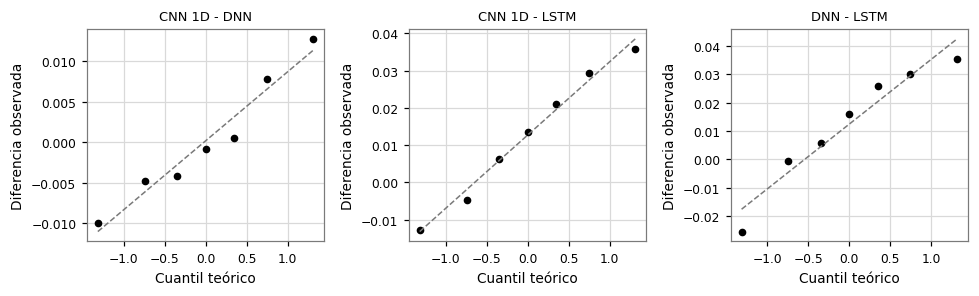

,Par,"Shapiro-Wilk, W","Shapiro-Wilk, p",Prueba elegida
0,CNN 1D - DNN,"0,9551","0,7754",t pareada
1,CNN 1D - LSTM,"0,9703","0,9006",t pareada
2,DNN - LSTM,"0,9326","0,5734",t pareada


**Interpretación.** Shapiro-Wilk no rechaza la normalidad en ninguno de los pares, y los gráficos Q-Q permiten verificar si las diferencias se apartan de la recta. La prueba de Brown-Forsythe da p = 0,865 para la igualdad de varianzas entre modelos.

Hay que tener en cuenta que con 7 observaciones estas pruebas tienen poca potencia, de modo que no rechazar la normalidad no la demuestra. Además, las semillas comparten el conjunto de prueba, por lo que la independencia se cumple solo respecto a la inicialización y al orden de los lotes, y no respecto a la muestra de datos.

Por lo anterior, se aplica la regla declarada para cada par y se reportan siempre las dos pruebas, además del *bootstrap* pareado, de modo que la conclusión no dependa de un único supuesto.

In [34]:
if hay_resultados:
    PARES = [(NOMBRES[i], NOMBRES[j]) for i in range(len(NOMBRES)) for j in range(i + 1, len(NOMBRES))]
    fig, ejes = plt.subplots(1, len(PARES), figsize=(3 * len(PARES), 2.8))
    filas_supuestos = []
    for eje, (a, b) in zip(np.atleast_1d(ejes), PARES):
        d = (MATRIZ_F1[a] - MATRIZ_F1[b]).to_numpy()
        (teoricos, ordenados), (pendiente, intercepto, _) = stats.probplot(d, dist="norm")
        eje.plot(teoricos, ordenados, "o", color=NEGRO, markersize=4)
        eje.plot(teoricos, pendiente * teoricos + intercepto, color=GRIS_MEDIO, linestyle="--", linewidth=1)
        eje.set(title=f"{a} - {b}", xlabel="Cuantil teórico", ylabel="Diferencia observada")
        eje.title.set_size(8.5)
        prueba_normal = stats.shapiro(d)
        filas_supuestos.append({"Par": f"{a} - {b}", "Shapiro-Wilk, W": prueba_normal.statistic, "Shapiro-Wilk, p": prueba_normal.pvalue, "Prueba elegida": "t pareada" if prueba_normal.pvalue >= ALFA else "Wilcoxon"})
    plt.tight_layout()
    plt.show()
    SUPUESTOS = pd.DataFrame(filas_supuestos)
    display(SUPUESTOS.round(4))
    brown_forsythe = stats.levene(*[MATRIZ_F1[n] for n in NOMBRES], center="median")
    rechazados = SUPUESTOS.loc[SUPUESTOS["Shapiro-Wilk, p"] < ALFA, "Par"].tolist()
    interpretar(f'''**Interpretación.** Shapiro-Wilk {"no rechaza la normalidad en ninguno de los pares" if not rechazados else "rechaza la normalidad en " + ", ".join(rechazados)}, y los gráficos Q-Q permiten verificar si las diferencias se apartan de la recta. La prueba de Brown-Forsythe da {valor_p(brown_forsythe.pvalue)} para la igualdad de varianzas entre modelos.

Hay que tener en cuenta que con {len(SEMILLAS)} observaciones estas pruebas tienen poca potencia, de modo que no rechazar la normalidad no la demuestra. Además, las semillas comparten el conjunto de prueba, por lo que la independencia se cumple solo respecto a la inicialización y al orden de los lotes, y no respecto a la muestra de datos.

Por lo anterior, se aplica la regla declarada para cada par y se reportan siempre las dos pruebas, además del *bootstrap* pareado, de modo que la conclusión no dependa de un único supuesto.''')

In [35]:
from scipy.optimize import brentq

Z_ALFA, Z_POTENCIA = stats.norm.ppf(1 - ALFA / 2), stats.norm.ppf(POTENCIA_OBJETIVO)
SIMULACIONES = 20000
FORMATO_POTENCIA = {"Potencia para δ": "{:.3f}", "Mínima detectable": "{:.4f}", "Mínima detectable por filas": "{:.4f}", "Mínima detectable por bloques": "{:.4f}"}


# Menor diferencia de una rejilla cuya potencia llega a la meta; cada simulación reutiliza los mismos números aleatorios
def primera_que_alcanza(potencia_de, tope, puntos=600):
    return next((d for d in np.linspace(0, tope, puntos + 1)[1:] if potencia_de(d) >= POTENCIA_OBJETIVO), np.nan)


# Valor crítico exacto de Wilcoxon bilateral, a partir de las 2^n asignaciones de signos
def critico_wilcoxon(n):
    sumas = ((np.arange(2 ** n)[:, None] >> np.arange(n)) & 1) @ np.arange(1, n + 1)
    w = np.minimum(sumas, n * (n + 1) / 2 - sumas)
    return max((c for c in np.unique(w) if (w <= c).mean() <= ALFA), default=-1)


# Potencia simulada de Wilcoxon exacto, con diferencias normales de media ``efecto``
def potencia_wilcoxon(desviacion, n, efecto, ruido):
    d = efecto + desviacion * ruido
    suma = ((np.abs(d).argsort(1).argsort(1) + 1) * (d > 0)).sum(1)
    return (np.minimum(suma, n * (n + 1) / 2 - suma) <= critico_wilcoxon(n)).mean()


# Potencia simulada de TOST con margen δ, si la diferencia real es nula
def potencia_tost(desviacion, n, ruido):
    d = desviacion * ruido
    media, error = d.mean(1), d.std(1, ddof=1) / np.sqrt(n)
    return (np.maximum(stats.t.sf((media + DELTA) / error, n - 1), stats.t.cdf((media - DELTA) / error, n - 1)) < ALFA).mean()


# ANOVA con Greenhouse-Geisser, si dos modelos difieren en ``diferencia`` y el tercero queda en el punto medio, la configuración menos favorable
def potencia_anova(diferencia, n, k, cuadrado_error, epsilon):
    gl1, gl2 = (k - 1) * epsilon, (k - 1) * (n - 1) * epsilon
    return stats.ncf.sf(stats.f.isf(ALFA, gl1, gl2), gl1, gl2, epsilon * n * diferencia ** 2 / (2 * cuadrado_error))


# Friedman y Nemenyi simulados con la misma configuración de medias y errores normales con el residuo medido
def potencia_rangos(diferencia, cuadrado_error, ruido, distancia_critica):
    y = np.array([diferencia / 2, 0, -diferencia / 2]) + np.sqrt(cuadrado_error) * ruido
    medios = ((-y).argsort(2).argsort(2) + 1).mean(1)
    chi2 = ruido.shape[1] * ((medios - 2) ** 2).sum(1)
    return (stats.chi2.sf(chi2, 2) < ALFA).mean(), (np.abs(medios[:, 0] - medios[:, 2]) > distancia_critica).mean()


# Prueba t con un error estándar dado, como el corregido de Nadeau y Bengio
def potencia_t_error(error, gl, diferencia):
    critico = stats.t.ppf(1 - ALFA / 2, gl)
    return stats.nct.sf(critico, gl, abs(diferencia) / error) + stats.nct.cdf(-critico, gl, abs(diferencia) / error)


def minima_t_error(error, gl):
    return brentq(lambda d: potencia_t_error(error, gl, d) - POTENCIA_OBJETIVO, 1e-9, 8 * error)


def comparar_par(a, b, repeticiones=10000):
    a, b = np.asarray(a), np.asarray(b)
    d = a - b
    n, media, sd = len(d), d.mean(), d.std(ddof=1)
    error = sd / np.sqrt(n)
    margen = stats.t.ppf(0.975, n - 1) * error
    # Con varianza nula, la diferencia es exacta: solo hay evidencia si además es distinta de cero
    t_valor, p_t = stats.ttest_rel(a, b) if sd > 0 else (0.0, 1.0) if media == 0 else (np.inf, 0.0)
    p_w = stats.wilcoxon(d, alternative="two-sided").pvalue if np.any(d != 0) else 1.0
    rng = np.random.default_rng(42)
    muestras = d[rng.integers(0, n, (repeticiones, n))]
    ic_media = np.percentile(muestras.mean(1), [2.5, 97.5])
    desviaciones = muestras.std(1, ddof=1)
    efectos = np.divide(muestras.mean(1), desviaciones, out=np.full(repeticiones, np.nan), where=desviaciones > 0)
    ic_efecto = np.nanpercentile(efectos, [2.5, 97.5])
    rangos = rankdata(np.abs(d[d != 0]))
    r_biserial = (rangos[d[d != 0] > 0].sum() - rangos[d[d != 0] < 0].sum()) / rangos.sum() if rangos.size else 0.0
    cliff = np.sign(np.subtract.outer(a, b)).mean()
    # Prueba de equivalencia TOST con el margen declarado a priori
    p_tost = max(stats.t.sf((media + DELTA) / error, n - 1), stats.t.cdf((media - DELTA) / error, n - 1)) if sd > 0 else float(abs(media) >= DELTA)
    ruido = np.random.default_rng(42).standard_normal((SIMULACIONES, n))
    return {"Potencia de Wilcoxon para δ": potencia_wilcoxon(sd, n, DELTA, ruido), "Mínima detectable de Wilcoxon": primera_que_alcanza(lambda e: potencia_wilcoxon(sd, n, e, ruido), 8 * sd), "Potencia de TOST": potencia_tost(sd, n, ruido),
            "Diferencia media": media, "IC 95 % t": (media - margen, media + margen), "IC 95 % bootstrap": tuple(ic_media), "t": t_valor, "p t pareada": p_t, "p Wilcoxon": p_w, "d de Cohen pareada": media / sd if sd > 0 else 0.0 if media == 0 else np.inf,
            "IC 95 % de d": tuple(ic_efecto), "r biserial": r_biserial, "δ de Cliff": cliff, "P. de superioridad": (d > 0).mean() + 0.5 * (d == 0).mean(), "p TOST": p_tost, "Potencia para δ": potencia_pareada(sd, n, DELTA), "Mínima detectable": minima_detectable(sd, n) if sd > 0 else 0.0}


def anova_repetidas(M):
    n, k = M.shape
    gran = M.mean()
    ss_modelo = n * ((M.mean(0) - gran) ** 2).sum()
    ss_semilla = k * ((M.mean(1) - gran) ** 2).sum()
    ss_error = ((M - gran) ** 2).sum() - ss_modelo - ss_semilla
    gl_modelo, gl_error = k - 1, (k - 1) * (n - 1)
    f = (ss_modelo / gl_modelo) / (ss_error / gl_error)
    centro = np.eye(k) - 1 / k
    doble = centro @ np.cov(M, rowvar=False) @ centro
    epsilon = np.trace(doble) ** 2 / ((k - 1) * (doble ** 2).sum())
    return {"F": f, "gl modelo": gl_modelo, "gl error": gl_error, "épsilon GG": epsilon, "p sin corregir": stats.f.sf(f, gl_modelo, gl_error), "p GG": stats.f.sf(f, gl_modelo * epsilon, gl_error * epsilon),
            "η² parcial": ss_modelo / (ss_modelo + ss_error), "ss": {"Modelo": ss_modelo, "Semilla": ss_semilla, "Residuo": ss_error}}


def nemenyi(M):
    n, k = M.shape
    rangos = np.apply_along_axis(lambda f: rankdata(-f), 1, M).mean(0)
    escala = np.sqrt(k * (k + 1) / (6 * n))
    valores = []
    for i in range(k):
        for j in range(i + 1, k):
            valores.append(studentized_range.sf(abs(rangos[i] - rangos[j]) / escala * np.sqrt(2), k, np.inf))
    return rangos, valores, studentized_range.ppf(0.95, k, np.inf) / np.sqrt(2) * escala


if hay_resultados:
    resultados_pares = {f"{a} - {b}": comparar_par(MATRIZ_F1[a], MATRIZ_F1[b]) for a, b in PARES}
    elegida = dict(zip(SUPUESTOS["Par"], SUPUESTOS["Prueba elegida"]))
    p_elegidos = np.array([resultados_pares[par]["p t pareada" if elegida[par] == "t pareada" else "p Wilcoxon"] for par in resultados_pares])
    p_holm = multipletests(p_elegidos, alpha=ALFA, method="holm")[1]
    p_holm_t = multipletests([r["p t pareada"] for r in resultados_pares.values()], alpha=ALFA, method="holm")[1]
    p_holm_w = multipletests([r["p Wilcoxon"] for r in resultados_pares.values()], alpha=ALFA, method="holm")[1]
    tabla_pares = pd.DataFrame([{"Par": par, "Diferencia media": round(r["Diferencia media"], 5), "IC 95 % t": f"[{num(r['IC 95 % t'][0], 4)}; {num(r['IC 95 % t'][1], 4)}]", "IC 95 % bootstrap": f"[{num(r['IC 95 % bootstrap'][0], 4)}; {num(r['IC 95 % bootstrap'][1], 4)}]",
                                 "Prueba elegida": elegida[par], "p sin ajustar": p_exacto(p), "p Holm": p_exacto(h), "p t": p_exacto(r["p t pareada"]), "p t Holm": p_exacto(ht), "p Wilcoxon": p_exacto(r["p Wilcoxon"]), "p Wilcoxon Holm": p_exacto(hw),
                                 "d de Cohen pareada": round(r["d de Cohen pareada"], 3), "IC 95 % de d": f"[{num(r['IC 95 % de d'][0], 2)}; {num(r['IC 95 % de d'][1], 2)}]", "r biserial": round(r["r biserial"], 3), "δ de Cliff": round(r["δ de Cliff"], 3), "P. de superioridad": round(r["P. de superioridad"], 3),
                                 "Potencia para δ": round(r["Potencia para δ"], 3), "Mínima detectable": round(r["Mínima detectable"], 5), "Potencia de Wilcoxon para δ": round(r["Potencia de Wilcoxon para δ"], 3), "Mínima detectable de Wilcoxon": round(r["Mínima detectable de Wilcoxon"], 5), "p TOST": p_exacto(r["p TOST"]), "Potencia de TOST": round(r["Potencia de TOST"], 3)} for (par, r), p, h, ht, hw in zip(resultados_pares.items(), p_elegidos, p_holm, p_holm_t, p_holm_w)]).set_index("Par").T
    display(tabla_pares)
    tabla_pares.to_csv(RESULTADOS / "comparaciones_pareadas.csv")

    M = MATRIZ_F1.to_numpy()
    anova = anova_repetidas(M)
    friedman = stats.friedmanchisquare(*M.T)
    kendall = friedman.statistic / (M.shape[0] * (M.shape[1] - 1))
    rangos_medios, p_nemenyi, distancia_critica = nemenyi(M)
    cuadrado_error = anova["ss"]["Residuo"] / anova["gl error"]
    n_semillas, k_modelos = M.shape
    potencia_global = potencia_anova(DELTA, n_semillas, k_modelos, cuadrado_error, anova["épsilon GG"])
    minima_global = brentq(lambda d: potencia_anova(d, n_semillas, k_modelos, cuadrado_error, anova["épsilon GG"]) - POTENCIA_OBJETIVO, 1e-9, 8 * np.sqrt(cuadrado_error))
    ruido_rangos = np.random.default_rng(42).standard_normal((SIMULACIONES, n_semillas, k_modelos))
    potencia_friedman, potencia_nemenyi = potencia_rangos(DELTA, cuadrado_error, ruido_rangos, distancia_critica)
    minima_friedman = primera_que_alcanza(lambda d: potencia_rangos(d, cuadrado_error, ruido_rangos, distancia_critica)[0], 10 * np.sqrt(cuadrado_error))
    minima_nemenyi = primera_que_alcanza(lambda d: potencia_rangos(d, cuadrado_error, ruido_rangos, distancia_critica)[1], 10 * np.sqrt(cuadrado_error))
    display(pd.DataFrame({"Prueba": ["ANOVA de medidas repetidas (Greenhouse-Geisser)", "Friedman"], "Estadístico": [round(anova["F"], 3), round(friedman.statistic, 3)], "p": [p_exacto(anova["p GG"]), p_exacto(friedman.pvalue)],
                          "Tamaño de efecto": [f"η² parcial = {num(anova['η² parcial'], 3)}", f"W de Kendall = {num(kendall, 3)}"], "Potencia para δ": [round(potencia_global, 3), round(potencia_friedman, 3)], "Mínima detectable": [round(minima_global, 5), round(minima_friedman, 5)]}).style.hide(axis="index").format(FORMATO_POTENCIA, decimal=","))
    display(pd.DataFrame({"Par": list(resultados_pares), "Diferencia de rangos": [abs(rangos_medios[i] - rangos_medios[j]) for i in range(3) for j in range(i + 1, 3)], "p Nemenyi": [p_exacto(v) for v in p_nemenyi],
                          "Potencia para δ": round(potencia_nemenyi, 3), "Mínima detectable": round(minima_nemenyi, 5)}).style.hide(axis="index").format(FORMATO_POTENCIA, decimal=","))
    ss_total = sum(anova["ss"].values())
    varianza = pd.DataFrame({"Suma de cuadrados": anova["ss"], "Porcentaje": {k: 100 * v / ss_total for k, v in anova["ss"].items()}})
    display(varianza.round(6))

    significativos = [par for par, h in zip(resultados_pares, p_holm) if h < ALFA]
    relevantes = [par for par in resultados_pares if abs(resultados_pares[par]["Diferencia media"]) >= DELTA]
    equivalentes = [par for par in resultados_pares if resultados_pares[par]["p TOST"] < ALFA]
    inciertos = [par for par in relevantes if par not in significativos]
    if not equivalentes:
        texto_equivalencia = "ningún par se puede declarar equivalente"
    else:
        texto_equivalencia = ("se declara equivalente, dentro de ±δ, el par " if len(equivalentes) == 1 else "se declaran equivalentes, dentro de ±δ, los pares ") + enumerar(equivalentes)
        if all(resultados_pares[par]["p TOST"] * 3 < ALFA for par in equivalentes):
            texto_equivalencia += ", conclusión que se mantiene al multiplicar el valor p por las tres comparaciones"
    p_min_wilcoxon = 2 / 2 ** len(SEMILLAS)
    interpretar(f'''**Interpretación.** Tras la corrección de Holm (1979), {"ningún par difiere de forma significativa" if not significativos else "difieren de forma significativa " + enumerar(significativos)}. La ANOVA de medidas repetidas da $F$ = {num(anova["F"], 2)} con {valor_p(anova["p GG"])} tras la corrección de Greenhouse-Geisser, y la prueba de Friedman (1937) da χ² = {num(friedman.statistic, 2)} con {valor_p(friedman.pvalue)} y una W de Kendall de {num(kendall, 3)}; la distancia crítica de Nemenyi es de {num(distancia_critica, 2)} rangos (Demšar, 2006). En la descomposición de la varianza, el modelo explica el {num(varianza.loc["Modelo", "Porcentaje"], 1)} %, la semilla el {num(varianza.loc["Semilla", "Porcentaje"], 1)} % y el residuo el {num(varianza.loc["Residuo", "Porcentaje"], 1)} %. En potencia, con el residuo medido y suponiendo que dos modelos difieren en δ y el tercero queda en el punto medio, que es la configuración menos favorable, la ANOVA alcanza {num(potencia_global, 2)} y su diferencia mínima detectable es de {num(minima_global, 4)}; Friedman, {num(potencia_friedman, 2)} y {num(minima_friedman, 4)}, y Nemenyi, {num(potencia_nemenyi, 2)} y {num(minima_nemenyi, 4)}, estas dos últimas por simulación. Entre los pares, Wilcoxon alcanza de {num(min(r["Potencia de Wilcoxon para δ"] for r in resultados_pares.values()), 2)} a {num(max(r["Potencia de Wilcoxon para δ"] for r in resultados_pares.values()), 2)} para δ, con una mínima detectable de {num(min(r["Mínima detectable de Wilcoxon"] for r in resultados_pares.values()), 4)} a {num(max(r["Mínima detectable de Wilcoxon"] for r in resultados_pares.values()), 4)}, y TOST, si la diferencia real fuera nula, de {num(min(r["Potencia de TOST"] for r in resultados_pares.values()), 2)} a {num(max(r["Potencia de TOST"] for r in resultados_pares.values()), 2)}.

Es decir, hay que distinguir dos preguntas. En significancia estadística, {"no hay evidencia de que algún par difiera" if not significativos else "hay evidencia de diferencia en " + enumerar(significativos)}. En relevancia práctica, {"ninguna diferencia media alcanza" if not relevantes else "la diferencia media de " + enumerar(relevantes) + " supera"} δ = {num(DELTA, 2)}{"" if not inciertos else f", pero sin significancia y con una potencia que va de {num(min(resultados_pares[par]['Potencia para δ'] for par in inciertos), 2)} a {num(max(resultados_pares[par]['Potencia para δ'] for par in inciertos), 2)}, de modo que el resultado en esos pares es no concluyente"}. La equivalencia se evalúa aparte con TOST (Schuirmann, 1987): {texto_equivalencia}. Así mismo, con {len(SEMILLAS)} pares el valor p mínimo de Wilcoxon es {num(p_min_wilcoxon, 4)}, de modo que {"esta prueba no podría superar el nivel más exigente de Holm, α/3 = 0,0167" if p_min_wilcoxon > ALFA / 3 else "esta prueba sí puede superar el nivel más exigente de Holm, α/3 = 0,0167"}. {"Además, con esas potencias, el no rechazo de las pruebas globales no descarta una diferencia de magnitud δ" if max(potencia_global, potencia_friedman, potencia_nemenyi) < POTENCIA_OBJETIVO else "Además, las pruebas globales tienen potencia suficiente para detectar una diferencia de magnitud δ"}, y donde TOST tiene potencia baja, como en los pares con LSTM, tampoco podría declararse equivalencia aunque existiera.

Por tanto, corresponde apoyar la decisión en la diferencia media con su intervalo y en el tamaño de efecto, y no solo en el valor p. Una ausencia de significancia no se interpreta como equivalencia.''')

Par,CNN 1D - DNN,CNN 1D - LSTM,DNN - LSTM
Diferencia media,"0,00018","0,01267","0,01249"
IC 95 % t,"[-0,0070; 0,0074]","[-0,0037; 0,0291]","[-0,0071; 0,0321]"
IC 95 % bootstrap,"[-0,0049; 0,0057]","[0,0005; 0,0247]","[-0,0030; 0,0257]"
Prueba elegida,t pareada,t pareada,t pareada
p sin ajustar,"0,95379","0,10764","0,16962"
p Holm,"0,95379","0,32291","0,33923"
p t,"0,95379","0,10764","0,16962"
p t Holm,"0,95379","0,32291","0,33923"
p Wilcoxon,"0,93750","0,10938","0,15625"
p Wilcoxon Holm,"0,93750","0,32812","0,32812"


Prueba,Estadístico,p,Tamaño de efecto,Potencia para δ,Mínima detectable
ANOVA de medidas repetidas (Greenhouse-Geisser),"2,6900","0,14306","η² parcial = 0,310","0,173","0,0276"
Friedman,"2,0000","0,36788","W de Kendall = 0,143","0,186","0,0258"


Par,Diferencia de rangos,p Nemenyi,Potencia para δ,Mínima detectable
CNN 1D - DNN,"0,1429","0,96139","0,142","0,0262"
CNN 1D - LSTM,"0,5714","0,53334","0,142","0,0262"
DNN - LSTM,"0,7143","0,37498","0,142","0,0262"


,Suma de cuadrados,Porcentaje
Modelo,"0,00074","24,27107"
Semilla,"0,00066","21,59715"
Residuo,"0,00165","54,13178"


**Interpretación.** Tras la corrección de Holm (1979), ningún par difiere de forma significativa. La ANOVA de medidas repetidas da $F$ = 2,69 con p = 0,143 tras la corrección de Greenhouse-Geisser, y la prueba de Friedman (1937) da χ² = 2,00 con p = 0,368 y una W de Kendall de 0,143; la distancia crítica de Nemenyi es de 1,25 rangos (Demšar, 2006). En la descomposición de la varianza, el modelo explica el 24,3 %, la semilla el 21,6 % y el residuo el 54,1 %. En potencia, con el residuo medido y suponiendo que dos modelos difieren en δ y el tercero queda en el punto medio, que es la configuración menos favorable, la ANOVA alcanza 0,17 y su diferencia mínima detectable es de 0,0276; Friedman, 0,19 y 0,0258, y Nemenyi, 0,14 y 0,0262, estas dos últimas por simulación. Entre los pares, Wilcoxon alcanza de 0,17 a 0,77 para δ, con una mínima detectable de 0,0105 a 0,0285, y TOST, si la diferencia real fuera nula, de 0,02 a 0,82.

Es decir, hay que distinguir dos preguntas. En significancia estadística, no hay evidencia de que algún par difiera. En relevancia práctica, la diferencia media de CNN 1D - LSTM y DNN - LSTM supera δ = 0,01, pero sin significancia y con una potencia que va de 0,18 a 0,24, de modo que el resultado en esos pares es no concluyente. La equivalencia se evalúa aparte con TOST (Schuirmann, 1987): se declara equivalente, dentro de ±δ, el par CNN 1D - DNN, conclusión que se mantiene al multiplicar el valor p por las tres comparaciones. Así mismo, con 7 pares el valor p mínimo de Wilcoxon es 0,0156, de modo que esta prueba sí puede superar el nivel más exigente de Holm, α/3 = 0,0167. Además, con esas potencias, el no rechazo de las pruebas globales no descarta una diferencia de magnitud δ, y donde TOST tiene potencia baja, como en los pares con LSTM, tampoco podría declararse equivalencia aunque existiera.

Por tanto, corresponde apoyar la decisión en la diferencia media con su intervalo y en el tamaño de efecto, y no solo en el valor p. Una ausencia de significancia no se interpreta como equivalencia.

In [36]:
def delong(verdad, puntaje_a, puntaje_b):
    m, n = int(verdad.sum()), int((~verdad).sum())
    componentes = []
    for puntaje in (puntaje_a, puntaje_b):
        pos, neg = puntaje[verdad], puntaje[~verdad]
        tx, ty = rankdata(pos), rankdata(neg)
        tz = rankdata(np.concatenate([pos, neg]))
        componentes.append(((tz[:m].sum() - m * (m + 1) / 2) / (m * n), (tz[:m] - tx) / n, 1 - (tz[m:] - ty) / m))
    (auc_a, v10_a, v01_a), (auc_b, v10_b, v01_b) = componentes
    cov_10, cov_01 = np.cov(v10_a, v10_b), np.cov(v01_a, v01_b)
    varianza = (cov_10[0, 0] + cov_10[1, 1] - 2 * cov_10[0, 1]) / m + (cov_01[0, 0] + cov_01[1, 1] - 2 * cov_01[0, 1]) / n
    return auc_a - auc_b, 2 * stats.norm.sf(abs(auc_a - auc_b) / np.sqrt(varianza)) if varianza > 0 else 1.0, np.sqrt(max(varianza, 0))


def f1_macro_rapido(verdad, prediccion, k=len(CLASES)):
    confusion = np.bincount(k * verdad + prediccion, minlength=k * k).reshape(k, k)
    return np.mean(2 * np.diag(confusion) / np.maximum(confusion.sum(0) + confusion.sum(1), 1))


# AUC con pesos sobre puntajes ya agrupados por empates, para recalcularlo rápido en cada remuestreo
def auc_ponderado(positivos, grupos, n_grupos, pesos):
    pos = np.bincount(grupos, weights=pesos * positivos, minlength=n_grupos)
    neg = np.bincount(grupos, weights=pesos * ~positivos, minlength=n_grupos)
    return (pos * (np.cumsum(neg) - neg / 2)).sum() / (pos.sum() * neg.sum())


def potencia_z(error, diferencia):
    return stats.norm.sf(Z_ALFA - diferencia / error) + stats.norm.sf(Z_ALFA + diferencia / error)


if hay_resultados:
    filas_mcnemar, filas_delong = [], []
    for a, b in PARES:
        p_mcnemar, discordantes, diferencias_exactitud, pruebas_delong = [], [], [], []
        for s in SEMILLAS:
            pa, pb = PROBABILIDADES[(a, s)], PROBABILIDADES[(b, s)]
            acierto_a, acierto_b = pa.argmax(1) == y_prueba, pb.argmax(1) == y_prueba
            n01, n10 = int((acierto_a & ~acierto_b).sum()), int((~acierto_a & acierto_b).sum())
            tabla = [[int((acierto_a & acierto_b).sum()), n01], [n10, int((~acierto_a & ~acierto_b).sum())]]
            p_mcnemar.append(mcnemar(tabla, exact=n01 + n10 < 25, correction=True).pvalue)
            discordantes.append(n01 + n10)
            diferencias_exactitud.append(acierto_a.mean() - acierto_b.mean())
            pruebas_delong.append([delong(y_prueba == c, pa[:, c], pb[:, c]) for c in range(len(CLASES))])
        pruebas_delong = np.array(pruebas_delong)
        ajustados = np.array([multipletests(fila, method="holm")[1] for fila in pruebas_delong[:, :, 1]])
        filas_mcnemar.append({"Par": f"{a} - {b}", "Diferencia media de accuracy": np.mean(diferencias_exactitud), "Discordantes (media)": np.mean(discordantes), "p de McNemar (mediana)": p_exacto(np.median(p_mcnemar)), "p mínimo": p_exacto(np.min(p_mcnemar)), "p máximo": p_exacto(np.max(p_mcnemar)),
                              "Semillas con p Holm < 0,05": f"{int((multipletests(p_mcnemar, method='holm')[1] < ALFA).sum())} de {len(SEMILLAS)}",
                              "Potencia para δ": np.median(potencia_z(np.sqrt(discordantes) / len(y_prueba), DELTA)), "Mínima detectable": (Z_ALFA + Z_POTENCIA) * np.median(np.sqrt(discordantes)) / len(y_prueba)})
        filas_delong.append({"Par": f"{a} - {b}", "Diferencia media de AUC por clase": pruebas_delong[:, :, 0].mean(), "Clase × semilla con p Holm < 0,05": f"{int((ajustados < ALFA).sum())} de {ajustados.size}", "p DeLong (mediana)": p_exacto(np.median(pruebas_delong[:, :, 1])),
                             "Potencia para δ": np.median(potencia_z(pruebas_delong[:, :, 2], DELTA)), "Mínima detectable": (Z_ALFA + Z_POTENCIA) * np.median(pruebas_delong[:, :, 2])})
    TABLA_MCNEMAR, TABLA_DELONG = pd.DataFrame(filas_mcnemar), pd.DataFrame(filas_delong)

    # Bootstrap estratificado por clase sobre el conjunto de prueba: captura la incertidumbre por la muestra de datos
    rng = np.random.default_rng(42)
    posiciones = [np.where(y_prueba == c)[0] for c in range(len(CLASES))]
    REPETICIONES_PRUEBA = 1000
    predicciones = {n: np.stack([PROBABILIDADES[(n, s)].argmax(1) for s in SEMILLAS]) for n in NOMBRES}
    distribucion = {n: np.empty(REPETICIONES_PRUEBA) for n in NOMBRES}
    # El mismo remuestreo da los intervalos de accuracy y de AUC macro, que McNemar y DeLong no entregan como promedio entre semillas
    grupos_auc = {n: [[np.unique(PROBABILIDADES[(n, s)][:, c], return_inverse=True)[1] for c in range(len(CLASES))] for s in SEMILLAS] for n in NOMBRES}
    positivos_auc = [y_prueba == c for c in range(len(CLASES))]
    extra_filas = {n: np.empty((REPETICIONES_PRUEBA, 2)) for n in NOMBRES}
    extra_bloques = {n: np.empty((REPETICIONES_PRUEBA, 2)) for n in NOMBRES}

    def exactitud_y_auc(nombre, muestra):
        pesos = np.bincount(muestra, minlength=len(y_prueba)).astype(float)
        exactitud = ((predicciones[nombre] == y_prueba) @ pesos).mean() / pesos.sum()
        return exactitud, np.mean([auc_ponderado(positivos_auc[c], grupos[c], grupos[c].max() + 1, pesos) for grupos in grupos_auc[nombre] for c in range(len(CLASES))])

    for repeticion in range(REPETICIONES_PRUEBA):
        muestra = np.concatenate([rng.choice(p, len(p), replace=True) for p in posiciones])
        for n in NOMBRES:
            distribucion[n][repeticion] = np.mean([f1_macro_rapido(y_prueba[muestra], fila[muestra]) for fila in predicciones[n]])
            extra_filas[n][repeticion] = exactitud_y_auc(n, muestra)
    limites ={f"{a} - {b}": np.percentile(distribucion[a] - distribucion[b], [2.5, 97.5]) for a, b in PARES}

    # Remuestreo por bloques: respeta la unidad de independencia, y se estratifica por la clase dominante de cada bloque
    bloques_prueba = (datos["FlowID"].to_numpy()[particion["prueba"]] - 1) // int(preparados["largo_bloque"])
    dominante = pd.Series(y_prueba).groupby(bloques_prueba).agg(lambda s: s.value_counts().index[0])
    posiciones_bloque = {b: np.where(bloques_prueba == b)[0] for b in dominante.index}
    estratos = [dominante.index[dominante == c].to_numpy() for c in range(len(CLASES)) if (dominante == c).any()]
    distribucion_bloques = {n: np.empty(REPETICIONES_PRUEBA) for n in NOMBRES}
    for repeticion in range(REPETICIONES_PRUEBA):
        muestra = np.concatenate([posiciones_bloque[b] for estrato in estratos for b in rng.choice(estrato, len(estrato), replace=True)])
        for n in NOMBRES:
            distribucion_bloques[n][repeticion] = np.mean([f1_macro_rapido(y_prueba[muestra], fila[muestra]) for fila in predicciones[n]])
            extra_bloques[n][repeticion] = exactitud_y_auc(n, muestra)
    limites_bloques = {f"{a} - {b}": np.percentile(distribucion_bloques[a] - distribucion_bloques[b], [2.5, 97.5]) for a, b in PARES}
    FACTOR_MINIMA = Z_ALFA + Z_POTENCIA

    # Diferencia entre dos modelos por remuestreo, por filas y por bloques
    def fila_remuestreo(metrica, a, b, por_filas, por_bloques):
        filas, bloques = por_filas[a] - por_filas[b], por_bloques[a] - por_bloques[b]
        lf, lb = np.percentile(filas, [2.5, 97.5]), np.percentile(bloques, [2.5, 97.5])
        return {"Métrica": metrica, "Par": f"{a} - {b}", "Diferencia media": float(filas.mean()), "IC 95 % por filas": f"[{num(lf[0], 4)}; {num(lf[1], 4)}]", "IC 95 % por bloques": f"[{num(lb[0], 4)}; {num(lb[1], 4)}]",
                "Mínima detectable por filas": FACTOR_MINIMA * filas.std(ddof=1), "Mínima detectable por bloques": FACTOR_MINIMA * bloques.std(ddof=1), "Excluye cero": not lb[0] <= 0 <= lb[1]}

    def columna_extra(extra, columna):
        return {n: extra[n][:, columna] for n in NOMBRES}

    TABLA_BOOTSTRAP = pd.DataFrame([fila_remuestreo("F1 macro", a, b, distribucion, distribucion_bloques) for a, b in PARES]
                                   + [fila_remuestreo("Accuracy", a, b, columna_extra(extra_filas, 0), columna_extra(extra_bloques, 0)) for a, b in PARES]
                                   + [fila_remuestreo("AUC macro", a, b, columna_extra(extra_filas, 1), columna_extra(extra_bloques, 1)) for a, b in PARES])
    F1_REMUESTREO = TABLA_BOOTSTRAP[TABLA_BOOTSTRAP["Métrica"] == "F1 macro"]
    excluye_extra = int(TABLA_BOOTSTRAP.loc[TABLA_BOOTSTRAP["Métrica"] != "F1 macro", "Excluye cero"].sum())
    display(TABLA_MCNEMAR.round(5).style.hide(axis="index").format(FORMATO_POTENCIA, decimal=","))
    display(TABLA_DELONG.round(5).style.hide(axis="index").format(FORMATO_POTENCIA, decimal=","))
    display(TABLA_BOOTSTRAP.drop(columns="Excluye cero").round(5).style.hide(axis="index").format({**FORMATO_POTENCIA, "Diferencia media": "{:.4f}"}, decimal=","))
    ic_baseline = np.percentile(distribucion[BASELINE], [2.5, 97.5])
    ic_baseline_bloques = np.percentile(distribucion_bloques[BASELINE], [2.5, 97.5])
    sin_cero = [par for par, l in limites.items() if not l[0] <= 0 <= l[1]]
    sin_cero_bloques = [par for par, l in limites_bloques.items() if not l[0] <= 0 <= l[1]]
    interpretar(f'''**Interpretación.** Estas pruebas trabajan con cada observación de prueba, no con cada semilla. McNemar (1947) compara las tasas de error mediante los casos discordantes, $\\chi^2 = (|n_{{01}} - n_{{10}}| - 1)^2 / (n_{{01}} + n_{{10}})$, con su versión exacta si hay menos de 25, y DeLong et al. (1988) compara las curvas ROC correlacionadas. Como el problema es multiclase, DeLong se aplica uno contra el resto, por clase, con corrección de Holm dentro de cada semilla. Como cada semilla entrega una prueba, se reporta la mediana y el rango de los valores p. El *bootstrap* estratificado por clase (Efron y Tibshirani, 1993), con {REPETICIONES_PRUEBA} remuestreos de las filas de prueba, da para el baseline un IC 95 % de [{num(ic_baseline[0], 4)}; {num(ic_baseline[1], 4)}]{", y el intervalo de la diferencia excluye el cero en " + enumerar(sin_cero) if sin_cero else ", y ningún intervalo de diferencia excluye el cero"}. Como las filas de un bloque no son independientes, el remuestreo se repite con los {len(dominante)} bloques de prueba, dentro de su clase dominante, y el IC 95 % del baseline pasa a [{num(ic_baseline_bloques[0], 4)}; {num(ic_baseline_bloques[1], 4)}]{", con un intervalo de la diferencia que excluye el cero en " + enumerar(sin_cero_bloques) if sin_cero_bloques else ", y ningún intervalo de diferencia excluye el cero"}. La última tabla agrega, con los mismos remuestreos, el intervalo de la diferencia media de accuracy y de AUC macro, {"y con los bloques ninguno de esos intervalos excluye el cero" if excluye_extra == 0 else f"y con los bloques {excluye_extra} de esos 6 intervalos excluyen el cero"}.

Hay que tener en cuenta que, con unas {num(len(y_prueba), 0)} observaciones, McNemar y DeLong detectan diferencias muy pequeñas: con potencia de 0,80, la mínima detectable va de {num(TABLA_MCNEMAR["Mínima detectable"].min(), 4)} a {num(TABLA_MCNEMAR["Mínima detectable"].max(), 4)} en accuracy, y de {num(TABLA_DELONG["Mínima detectable"].min(), 4)} a {num(TABLA_DELONG["Mínima detectable"].max(), 4)} en el AUC de una clase, de modo que un valor p bajo aquí no implica relevancia práctica. Como δ se declaró sobre el F1 macro, en estas dos métricas la potencia para δ, {"prácticamente de 1" if min(TABLA_MCNEMAR["Potencia para δ"].min(), TABLA_DELONG["Potencia para δ"].min()) > 0.99 else "de al menos " + num(min(TABLA_MCNEMAR["Potencia para δ"].min(), TABLA_DELONG["Potencia para δ"].min()), 2)}, solo sirve como referencia de escala. Además, ambas pruebas y el *bootstrap* por filas suponen observaciones independientes, algo que la sección 2.1.3 descarta, de modo que sus valores p y sus intervalos resultan optimistas: al respetar los bloques, la mínima detectable en F1 macro sube de un rango de {num(F1_REMUESTREO["Mínima detectable por filas"].min(), 4)} a {num(F1_REMUESTREO["Mínima detectable por filas"].max(), 4)} por filas a uno de {num(F1_REMUESTREO["Mínima detectable por bloques"].min(), 4)} a {num(F1_REMUESTREO["Mínima detectable por bloques"].max(), 4)} por bloques. Por eso, el remuestreo por bloques es el que mejor mide lo que las semillas no miden, cuánto cambiaría la diferencia con otra muestra de bloques, aunque con tan pocos bloques su intervalo es solo aproximado.

Así las cosas, se decide reportar McNemar y DeLong como pide el enunciado, pero solo como apoyo, sin basar en ellas ninguna afirmación de superioridad, y juzgar la relevancia siempre contra δ = {num(DELTA, 2)}.''')

Par,Diferencia media de accuracy,Discordantes (media),p de McNemar (mediana),p mínimo,p máximo,"Semillas con p Holm < 0,05",Potencia para δ,Mínima detectable
CNN 1D - DNN,"0,0003","1003,5714","6,94e-06","3,09e-18","0,80453",5 de 7,"1,000","0,0038"
CNN 1D - LSTM,"0,0109","1680,8571","2,71e-12","4,44e-79","0,00038",7 de 7,"1,000","0,0051"
DNN - LSTM,"0,0106","1695,8571","2,17e-31","1,63e-74","0,32314",6 de 7,"1,000","0,0051"


Par,Diferencia media de AUC por clase,"Clase × semilla con p Holm < 0,05",p DeLong (mediana),Potencia para δ,Mínima detectable
CNN 1D - DNN,"0,0035",30 de 35,"8,11e-20","1,000","0,0010"
CNN 1D - LSTM,"-0,0092",32 de 35,"4,05e-28","1,000","0,0019"
DNN - LSTM,"-0,0127",31 de 35,"5,55e-34","1,000","0,0021"


Métrica,Par,Diferencia media,IC 95 % por filas,IC 95 % por bloques,Mínima detectable por filas,Mínima detectable por bloques
F1 macro,CNN 1D - DNN,"0,0002","[-0,0014; 0,0017]","[-0,0082; 0,0076]","0,0022","0,0116"
F1 macro,CNN 1D - LSTM,"0,0126","[0,0104; 0,0147]","[-0,0011; 0,0270]","0,0032","0,0207"
F1 macro,DNN - LSTM,"0,0124","[0,0100; 0,0149]","[-0,0058; 0,0326]","0,0035","0,0279"
Accuracy,CNN 1D - DNN,"0,0003","[-0,0012; 0,0018]","[-0,0077; 0,0084]","0,0022","0,0113"
Accuracy,CNN 1D - LSTM,"0,0108","[0,0087; 0,0128]","[-0,0038; 0,0239]","0,0030","0,0202"
Accuracy,DNN - LSTM,"0,0105","[0,0082; 0,0127]","[-0,0091; 0,0291]","0,0033","0,0278"
AUC macro,CNN 1D - DNN,"0,0035","[0,0032; 0,0038]","[-0,0001; 0,0093]","0,0004","0,0070"
AUC macro,CNN 1D - LSTM,"-0,0092","[-0,0103; -0,0080]","[-0,0345; 0,0043]","0,0016","0,0299"
AUC macro,DNN - LSTM,"-0,0127","[-0,0139; -0,0114]","[-0,0429; 0,0036]","0,0018","0,0364"


**Interpretación.** Estas pruebas trabajan con cada observación de prueba, no con cada semilla. McNemar (1947) compara las tasas de error mediante los casos discordantes, $\chi^2 = (|n_{01} - n_{10}| - 1)^2 / (n_{01} + n_{10})$, con su versión exacta si hay menos de 25, y DeLong et al. (1988) compara las curvas ROC correlacionadas. Como el problema es multiclase, DeLong se aplica uno contra el resto, por clase, con corrección de Holm dentro de cada semilla. Como cada semilla entrega una prueba, se reporta la mediana y el rango de los valores p. El *bootstrap* estratificado por clase (Efron y Tibshirani, 1993), con 1000 remuestreos de las filas de prueba, da para el baseline un IC 95 % de [0,8508; 0,8588], y el intervalo de la diferencia excluye el cero en CNN 1D - LSTM y DNN - LSTM. Como las filas de un bloque no son independientes, el remuestreo se repite con los 24 bloques de prueba, dentro de su clase dominante, y el IC 95 % del baseline pasa a [0,7661; 0,9182], y ningún intervalo de diferencia excluye el cero. La última tabla agrega, con los mismos remuestreos, el intervalo de la diferencia media de accuracy y de AUC macro, y con los bloques ninguno de esos intervalos excluye el cero.

Hay que tener en cuenta que, con unas 22 883 observaciones, McNemar y DeLong detectan diferencias muy pequeñas: con potencia de 0,80, la mínima detectable va de 0,0038 a 0,0051 en accuracy, y de 0,0010 a 0,0021 en el AUC de una clase, de modo que un valor p bajo aquí no implica relevancia práctica. Como δ se declaró sobre el F1 macro, en estas dos métricas la potencia para δ, prácticamente de 1, solo sirve como referencia de escala. Además, ambas pruebas y el *bootstrap* por filas suponen observaciones independientes, algo que la sección {ref}`2.1.3 <sec-2-1-3>` descarta, de modo que sus valores p y sus intervalos resultan optimistas: al respetar los bloques, la mínima detectable en F1 macro sube de un rango de 0,0023 a 0,0035 por filas a uno de 0,0116 a 0,0279 por bloques. Por eso, el remuestreo por bloques es el que mejor mide lo que las semillas no miden, cuánto cambiaría la diferencia con otra muestra de bloques, aunque con tan pocos bloques su intervalo es solo aproximado.

Así las cosas, se decide reportar McNemar y DeLong como pide el enunciado, pero solo como apoyo, sin basar en ellas ninguna afirmación de superioridad, y juzgar la relevancia siempre contra δ = 0,01.

### Validación cruzada repetida

Las semillas sobre una partición fija no miden la variabilidad que proviene de la selección de los datos. Por eso, como recomienda el enunciado, se agrega una validación cruzada repetida 5 × 5, agrupada por bloques y solo con entrenamiento y validación, de modo que la prueba sigue congelada. En cada pliegue, la transformación y los pesos de clase se ajustan con la parte de entrenamiento, y un 20 % de esa parte se usa para la parada temprana. Las diferencias pareadas se prueban con la corrección de varianza de Nadeau y Bengio (2003), $t = \bar{d} \,/\, \sqrt{\left(\frac{1}{kr} + \frac{n_2}{n_1}\right) \hat{\sigma}_d^2}$, porque los pliegues comparten datos de entrenamiento y la prueba sin corregir sería demasiado optimista.

In [37]:
REPETICIONES_CV, PLIEGUES_CV = 5, 5
RUTA_CV = RESULTADOS / "validacion_repetida.csv"
if hay_resultados:
    hiper = preregistro["hiperparametros"]
    largo = int(preparados["largo_bloque"])
    id_dev_np = np.concatenate([particion["entrenamiento"], particion["validacion"]])
    X_guardada, PESOS_GUARDADOS = X, PESOS
    X_log = torch.from_numpy(preparados["X"].astype(np.float64) * preparados["desviacion"] + preparados["media"]).float()
    hechas = pd.read_csv(RUTA_CV).to_dict("records") if RUTA_CV.exists() else []
    ya = {(f["Repetición"], f["Pliegue"], f["Modelo"]) for f in hechas}
    for rep in range(REPETICIONES_CV):
        pliegues = StratifiedGroupKFold(PLIEGUES_CV, shuffle=True, random_state=3000 + rep)
        for k, (pos_ajuste, pos_fuera) in enumerate(pliegues.split(id_dev_np, y_np[id_dev_np], id_dev_np // largo)):
            if all((rep, k, n) in ya for n in MODELOS):
                continue
            ajuste, fuera = id_dev_np[pos_ajuste], id_dev_np[pos_fuera]
            pos_a, pos_b = next(StratifiedGroupKFold(5, shuffle=True, random_state=3000 + rep).split(ajuste, y_np[ajuste], ajuste // largo))
            ids_a, ids_b = torch.from_numpy(ajuste[pos_a]), torch.from_numpy(ajuste[pos_b])
            X = (X_log - X_log[ids_a].mean(0)) / X_log[ids_a].std(0)
            frecuencia_k = np.bincount(y_np[ajuste[pos_a]], minlength=N_CLASES)
            PESOS = torch.from_numpy((frecuencia_k.sum() / (N_CLASES * frecuencia_k)).astype(np.float32))
            for nombre in MODELOS:
                if (rep, k, nombre) in ya:
                    continue
                modelo, _ = entrenar(nombre, hiper[nombre], 3000 + 100 * rep + k, ids_a, ids_b)
                pred_fuera = predecir(modelo, torch.from_numpy(fuera)).argmax(1).numpy()
                hechas.append({"Repetición": rep, "Pliegue": k, "Modelo": nombre, "F1 macro": f1_score(y_np[fuera], pred_fuera, average="macro", zero_division=0), "n ajuste": len(ajuste), "n fuera": len(fuera)})
                pd.DataFrame(hechas).to_csv(RUTA_CV, index=False)
            print(f"Validación repetida: repetición {rep + 1}, pliegue {k + 1}", flush=True)
    X, PESOS = X_guardada, PESOS_GUARDADOS
    cv = pd.DataFrame(hechas)
    matriz_cv = cv.pivot_table(index=["Repetición", "Pliegue"], columns="Modelo", values="F1 macro")[NOMBRES]
    n1_cv, n2_cv, kr = cv["n ajuste"].mean(), cv["n fuera"].mean(), len(matriz_cv)
    filas_cv = []
    for i in range(len(NOMBRES)):
        for j in range(i + 1, len(NOMBRES)):
            d_cv = matriz_cv[NOMBRES[i]] - matriz_cv[NOMBRES[j]]
            error_cv = np.sqrt((1 / kr + n2_cv / n1_cv) * d_cv.var(ddof=1))
            t_cv = d_cv.mean() / error_cv if error_cv > 0 else 0.0
            margen_cv = stats.t.ppf(0.975, kr - 1) * error_cv
            filas_cv.append({"Par": f"{NOMBRES[i]} - {NOMBRES[j]}", "Diferencia media": d_cv.mean(), "IC 95 % corregido": f"[{num(d_cv.mean() - margen_cv, 4)}; {num(d_cv.mean() + margen_cv, 4)}]", "t corregida": t_cv, "p sin ajustar": 2 * stats.t.sf(abs(t_cv), kr - 1), "P. de superioridad": (d_cv > 0).mean() + 0.5 * (d_cv == 0).mean(), "Potencia para δ": potencia_t_error(error_cv, kr - 1, DELTA), "Mínima detectable": minima_t_error(error_cv, kr - 1)})
    tabla_cv = pd.DataFrame(filas_cv)
    tabla_cv["p Holm"] = multipletests(tabla_cv["p sin ajustar"], method="holm")[1]
    resumen_cv = matriz_cv.agg(["mean", "std"]).T
    display(resumen_cv.rename(columns={"mean": "F1 macro medio", "std": "Desviación"}).round(4))
    display(tabla_cv.style.hide(axis="index").format({"Diferencia media": "{:.4f}", "t corregida": "{:.3f}", "p sin ajustar": p_exacto, "p Holm": p_exacto, "P. de superioridad": "{:.2f}", "Potencia para δ": "{:.3f}", "Mínima detectable": "{:.4f}"}, decimal=","))
    tabla_cv.to_csv(RESULTADOS / "comparaciones_validacion_repetida.csv", index=False)
    significativos_cv = tabla_cv.loc[tabla_cv["p Holm"] < ALFA, "Par"].tolist()
    interpretar(f'''**Interpretación.** Con {kr} pliegues, el F1 macro medio va de {num(resumen_cv["mean"].min(), 4)} a {num(resumen_cv["mean"].max(), 4)}, y la desviación entre pliegues llega a {num(resumen_cv["std"].max(), 4)}, mayor que la que producen las semillas sobre una partición fija, porque aquí también cambian los datos. Con la corrección de Nadeau y Bengio (2003), {"ningún par difiere de forma significativa" if not significativos_cv else "difieren de forma significativa: " + ", ".join(significativos_cv)} tras el ajuste de Holm. La potencia para detectar δ va de {num(tabla_cv["Potencia para δ"].min(), 2)} a {num(tabla_cv["Potencia para δ"].max(), 2)}, y la diferencia mínima detectable, de {num(tabla_cv["Mínima detectable"].min(), 4)} a {num(tabla_cv["Mínima detectable"].max(), 4)}.

Esto significa que la incertidumbre por la selección de los bloques pesa más que la de la inicialización. En ese sentido, una diferencia que parece clara entre semillas puede no sostenerse cuando cambia el conjunto de datos, y por eso esta prueba es la más exigente del estudio. {"Con esa mínima detectable, el no rechazo no descarta diferencias mayores que δ. " if tabla_cv["Mínima detectable"].min() > DELTA else ""}Hay que tener en cuenta que el estadístico corregido es conservador cuando los pliegues se solapan mucho.

Por tal motivo, se toma esta prueba como la referencia para afirmar que un modelo base supera a otro.''')

,F1 macro medio,Desviación
Modelo,,
CNN 1D,"0,8888","0,0382"
DNN,"0,8811","0,0417"
LSTM,"0,8649","0,0491"


Par,Diferencia media,IC 95 % corregido,t corregida,p sin ajustar,P. de superioridad,Potencia para δ,Mínima detectable,p Holm
CNN 1D - DNN,"0,0077","[-0,0082; 0,0236]","1,001","0,32697","0,76","0,238","0,0225","0,65394"
CNN 1D - LSTM,"0,0239","[-0,0058; 0,0536]","1,664","0,10919","0,84","0,103","0,0420","0,32756"
DNN - LSTM,"0,0162","[-0,0179; 0,0503]","0,979","0,33723","0,68","0,089","0,0483","0,65394"


**Interpretación.** Con 25 pliegues, el F1 macro medio va de 0,8649 a 0,8888, y la desviación entre pliegues llega a 0,0491, mayor que la que producen las semillas sobre una partición fija, porque aquí también cambian los datos. Con la corrección de Nadeau y Bengio (2003), ningún par difiere de forma significativa tras el ajuste de Holm. La potencia para detectar δ va de 0,09 a 0,24, y la diferencia mínima detectable, de 0,0225 a 0,0483.

Esto significa que la incertidumbre por la selección de los bloques pesa más que la de la inicialización. En ese sentido, una diferencia que parece clara entre semillas puede no sostenerse cuando cambia el conjunto de datos, y por eso esta prueba es la más exigente del estudio. Con esa mínima detectable, el no rechazo no descarta diferencias mayores que δ. Hay que tener en cuenta que el estadístico corregido es conservador cuando los pliegues se solapan mucho.

Por tal motivo, se toma esta prueba como la referencia para afirmar que un modelo base supera a otro.

### Análisis de sensibilidad del *dropout*

La sección {ref}`4.2 <sec-4-2>` declara que el *dropout* de los tres modelos difiere del código de los autores (Zeng, 2025). Para saber si esa desviación cambia las conclusiones, se entrenan de nuevo los tres modelos con el *dropout* original, con las mismas semillas, la misma partición y los mismos hiperparámetros, y se comparan por pares con las corridas definitivas. Este análisis se decidió después de conocer los resultados, de modo que no reemplaza al baseline preregistrado y solo mide cuánto depende de esa diferencia. Además, los hiperparámetros se eligieron sin este *dropout*, por lo que no están ajustados para estas variantes.

In [38]:
class DNNOriginal(nn.Module):
    def __init__(self, p=0.2):
        super().__init__()
        self.red = nn.Sequential(nn.Linear(N_ATRIBUTOS, 128), nn.ReLU(), nn.Dropout(p), nn.Linear(128, 64), nn.ReLU(), nn.Dropout(p), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, N_CLASES))

    def forward(self, x):
        return self.red(x)


class CNN1DOriginal(nn.Module):
    def __init__(self, p=0.2):
        super().__init__()
        self.convoluciones = nn.Sequential(nn.Conv1d(1, 32, 3, padding=1), nn.ReLU(), nn.Conv1d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool1d(2))
        self.densas = nn.Sequential(nn.Flatten(), nn.Dropout(p), nn.Linear(64 * (N_ATRIBUTOS // 2), 64), nn.ReLU(), nn.Linear(64, N_CLASES))

    def forward(self, x):
        return self.densas(self.convoluciones(x.unsqueeze(1)))


class LSTMOriginal(nn.Module):
    def __init__(self, p=0.2):
        super().__init__()
        self.lstm = nn.LSTM(1, 64, batch_first=True)
        self.salida = nn.Sequential(nn.Dropout(p), nn.Linear(64, N_CLASES))

    def forward(self, x):
        return self.salida(self.lstm(x.unsqueeze(-1))[1][0][-1])


VARIANTES = {"DNN": "DNN original", "CNN 1D": "CNN 1D original", "LSTM": "LSTM original"}
MODELOS.update({"DNN original": DNNOriginal, "CNN 1D original": CNN1DOriginal, "LSTM original": LSTMOriginal})
RUTA_SENSIBILIDAD = RESULTADOS / "sensibilidad"
RUTA_SENSIBILIDAD.mkdir(exist_ok=True)
if hay_resultados:
    filas_sens = []
    for nombre in NOMBRES:
        assert sum(p.numel() for p in MODELOS[nombre]().parameters()) == sum(p.numel() for p in MODELOS[VARIANTES[nombre]]().parameters())
        for semilla in SEMILLAS:
            ruta = RUTA_SENSIBILIDAD / f"{nombre.replace(' ', '_')}_{int(semilla)}.json"
            if not ruta.exists():
                inicio = time.time()
                modelo, curvas = entrenar(VARIANTES[nombre], preregistro["hiperparametros"][nombre], int(semilla), id_ent, id_val)
                registro = {"modelo": VARIANTES[nombre], "semilla": int(semilla), "hp": preregistro["hiperparametros"][nombre], "epocas": len(curvas), "segundos": round(time.time() - inicio, 1),
                            "f1_val": f1_score(Y[id_val].numpy(), predecir(modelo, id_val).argmax(1).numpy(), average="macro", zero_division=0),
                            "f1_prueba": f1_score(y_prueba, predecir(modelo, id_pru).argmax(1).numpy(), average="macro", zero_division=0),
                            "dispositivo": f"CPU, {torch.get_num_threads()} hilos, {platform.processor()}"}
                ruta.write_text(json.dumps(registro, ensure_ascii=False), encoding="utf-8")
                print(f"{VARIANTES[nombre]} | semilla {int(semilla)} | F1 de prueba {registro['f1_prueba']:.4f} | {registro['segundos'] / 60:.1f} min", flush=True)
            filas_sens.append({"Modelo": nombre, "Semilla": int(semilla), **{k: v for k, v in json.loads(ruta.read_text(encoding="utf-8")).items() if k in ("f1_prueba", "f1_val", "epocas", "segundos")}})
    SENS = pd.DataFrame(filas_sens)
    MATRIZ_SENS = SENS.pivot(index="Semilla", columns="Modelo", values="f1_prueba")[NOMBRES]
    resultados_sens = {n: comparar_par(MATRIZ_SENS[n], MATRIZ_F1[n]) for n in NOMBRES}
    holm_sens = multipletests([r["p t pareada"] for r in resultados_sens.values()], method="holm")[1]
    tabla_sens = pd.DataFrame([{"Modelo": n, "F1 macro definitivo": MATRIZ_F1[n].mean(), "F1 macro con dropout original": MATRIZ_SENS[n].mean(), "Desviación": MATRIZ_SENS[n].std(ddof=1), "Diferencia media": r["Diferencia media"],
                                "IC 95 % t": f"[{num(r['IC 95 % t'][0], 4)}; {num(r['IC 95 % t'][1], 4)}]", "p sin ajustar": p_exacto(r["p t pareada"]), "p Holm": p_exacto(h), "d de Cohen pareada": r["d de Cohen pareada"],
                                "Potencia para δ": r["Potencia para δ"], "Mínima detectable": r["Mínima detectable"], "p TOST": p_exacto(r["p TOST"])} for (n, r), h in zip(resultados_sens.items(), holm_sens)])
    display(tabla_sens.style.hide(axis="index").format({"F1 macro definitivo": "{:.4f}", "F1 macro con dropout original": "{:.4f}", "Desviación": "{:.4f}", "Diferencia media": "{:.4f}", "d de Cohen pareada": "{:.2f}", "Potencia para δ": "{:.3f}", "Mínima detectable": "{:.4f}"}, decimal=","))
    tabla_sens.to_csv(RESULTADOS / "sensibilidad_dropout.csv", index=False)
    pares_sens = {f"{a} - {b}": comparar_par(MATRIZ_SENS[a], MATRIZ_SENS[b]) for a, b in PARES}
    holm_pares_sens = multipletests([r["p t pareada"] for r in pares_sens.values()], method="holm")[1]
    tabla_pares_sens = pd.DataFrame([{"Par con dropout original": par, "Diferencia media": r["Diferencia media"], "IC 95 % t": f"[{num(r['IC 95 % t'][0], 4)}; {num(r['IC 95 % t'][1], 4)}]", "p sin ajustar": p_exacto(r["p t pareada"]), "p Holm": p_exacto(h),
                                      "d de Cohen pareada": r["d de Cohen pareada"], "Potencia para δ": r["Potencia para δ"], "p TOST": p_exacto(r["p TOST"])} for (par, r), h in zip(pares_sens.items(), holm_pares_sens)])
    display(tabla_pares_sens.style.hide(axis="index").format({"Diferencia media": "{:.4f}", "d de Cohen pareada": "{:.2f}", "Potencia para δ": "{:.3f}"}, decimal=","))
    orden_def = list(MATRIZ_F1.mean().sort_values(ascending=False).index)
    orden_sens = list(MATRIZ_SENS.mean().sort_values(ascending=False).index)
    mayor_cambio = tabla_sens.loc[tabla_sens["Diferencia media"].abs().idxmax()]
    relevantes_sens = [n for n, r in resultados_sens.items() if abs(r["Diferencia media"]) >= DELTA]
    significativos_sens = [n for n, h in zip(resultados_sens, holm_sens) if h < ALFA]
    equivalentes_sens = [n for n, r in resultados_sens.items() if r["p TOST"] < ALFA]
    pares_signif = [par for par, h in zip(pares_sens, holm_pares_sens) if h < ALFA]
    interpretar(f'''**Interpretación.** Con el *dropout* del código de los autores, el F1 macro de prueba es de {num(MATRIZ_SENS[orden_sens[0]].mean(), 4)} en {orden_sens[0]}, {num(MATRIZ_SENS[orden_sens[1]].mean(), 4)} en {orden_sens[1]} y {num(MATRIZ_SENS[orden_sens[2]].mean(), 4)} en {orden_sens[2]}. El mayor cambio frente a las corridas definitivas es el de {mayor_cambio["Modelo"]}, con una diferencia media de {num(mayor_cambio["Diferencia media"], 4)}. Tras la corrección de Holm, {"ningún modelo cambia de forma significativa" if not significativos_sens else "cambia de forma significativa " + enumerar(significativos_sens)}, y {"ninguna diferencia alcanza" if not relevantes_sens else "la diferencia de " + enumerar(relevantes_sens) + " alcanza"} δ = {num(DELTA, 2)}. Entre las variantes, {"ningún par difiere de forma significativa" if not pares_signif else "difieren de forma significativa " + enumerar(pares_signif)}.

Esto significa que el orden de los modelos {"se mantiene" if orden_sens == orden_def else "cambia, de " + ", ".join(orden_def) + " a " + ", ".join(orden_sens)}. Hay que tener en cuenta que no rechazar no demuestra equivalencia: {"TOST la respalda en " + enumerar(equivalentes_sens) if equivalentes_sens else "TOST no la respalda en ningún modelo"}, y la mínima detectable llega a {num(tabla_sens["Mínima detectable"].max(), 4)}. Además, este análisis usa la misma partición y hiperparámetros elegidos sin ese *dropout*.

Por tal motivo, {"se conserva el baseline preregistrado y se declara la desviación como una amenaza a la validez interna" if orden_sens[0] == orden_def[0] and not relevantes_sens else "se conserva el baseline preregistrado solo como referencia del protocolo declarado, y se recomienda repetir el diseño con la arquitectura original antes de heredarlo al Entregable 2"}.''')

Modelo,F1 macro definitivo,F1 macro con dropout original,Desviación,Diferencia media,IC 95 % t,p sin ajustar,p Holm,d de Cohen pareada,Potencia para δ,Mínima detectable,p TOST
CNN 1D,"0,8549","0,8610","0,0082","0,0061","[-0,0059; 0,0181]","0,26215","0,78645","0,47","0,404","0,0165","0,22652"
DNN,"0,8548","0,8582","0,0111","0,0035","[-0,0070; 0,0139]","0,45022","0,90045","0,31","0,501","0,0144","0,08835"
LSTM,"0,8423","0,8357","0,0263","-0,0066","[-0,0285; 0,0154]","0,49023","0,90045","-0,28","0,157","0,0302","0,35838"


Par con dropout original,Diferencia media,IC 95 % t,p sin ajustar,p Holm,d de Cohen pareada,Potencia para δ,p TOST
CNN 1D - DNN,"0,0028","[-0,0046; 0,0102]","0,39333","0,39333","0,35","0,783","0,02762"
CNN 1D - LSTM,"0,0253","[0,0038; 0,0469]","0,02817","0,08451","1,09","0,161","0,93382"
DNN - LSTM,"0,0225","[-0,0004; 0,0455]","0,05299","0,10599","0,91","0,148","0,88518"


**Interpretación.** Con el *dropout* del código de los autores, el F1 macro de prueba es de 0,8610 en CNN 1D, 0,8582 en DNN y 0,8357 en LSTM. El mayor cambio frente a las corridas definitivas es el de LSTM, con una diferencia media de -0,0066. Tras la corrección de Holm, ningún modelo cambia de forma significativa, y ninguna diferencia alcanza δ = 0,01. Entre las variantes, ningún par difiere de forma significativa.

Esto significa que el orden de los modelos se mantiene. Hay que tener en cuenta que no rechazar no demuestra equivalencia: TOST no la respalda en ningún modelo, y la mínima detectable llega a 0,0302. Además, este análisis usa la misma partición y hiperparámetros elegidos sin ese *dropout*.

Por tal motivo, se conserva el baseline preregistrado y se declara la desviación como una amenaza a la validez interna.

(sec-5-5)=
## 5.5 Discusión crítica

Esta subsección responde las preguntas del enunciado con la evidencia de las secciones 4.4 y 5.1 a 5.4. El resultado central es que el estudio fija un baseline y un umbral, pero no permite ordenar con certeza a los tres modelos, porque dos de ellos son equivalentes en esta partición y el tercero queda en un resultado no concluyente.

**Qué modelo funciona mejor y por qué.** Por F1 macro, CNN 1D (0,8549) y DNN (0,8548) quedan empatadas, y LSTM queda por detrás (0,8423). CNN 1D es la primera y por eso es el baseline, como indica el enunciado, pero su ventaja de 0,0002 no tiene peso alguno: gana en 3 de las 7 semillas, y TOST declara equivalentes a los dos modelos dentro de ±0,01 (p = 0,0079). En sesgo inductivo, la convolución y la LSTM suponen que la posición en el vector tiene significado, mientras que aquí el orden es solo el de las columnas del archivo (sección {ref}`2.2.2 <sec-2-2-2>`). Que CNN 1D iguale a DNN con 3,1 veces sus parámetros sugiere que la localidad no aporta sobre las conexiones densas, y que LSTM quede atrás es coherente con que deba resumir en un estado de 64 unidades una secuencia de 16 pasos sin sentido temporal. En capacidad y regularización, LSTM es además el modelo más sensible a los hiperparámetros, con un rango de 0,073 en la búsqueda; su configuración elegida no tiene *weight decay* ni, por la desviación declarada en la sección {ref}`4.2 <sec-4-2>`, *dropout*, y muestra la mayor brecha entre entrenamiento y validación, 0,037 frente a 0,005 en CNN 1D y 0,001 en DNN. El análisis de sensibilidad de la sección {ref}`5.4 <sec-5-4>` tampoco respalda que la falta de *dropout* explique el rezago de LSTM: con él, su F1 macro baja a 0,8357 y su desviación sube a 0,0263, y la distancia con CNN 1D crece a 0,0253. Hay que tener en cuenta que estas explicaciones son plausibles, pero no están demostradas, porque el diseño compara tres arquitecturas completas y no aísla cada factor.

El orden, además, depende de la métrica. LSTM, la última por F1 macro, obtiene el mayor AUC-ROC macro (0,9728, frente a 0,9637 en CNN 1D y 0,9602 en DNN), el mayor AUC-PR macro (0,8791, frente a 0,8511 y 0,8336) y el menor ECE (0,0402, frente a 0,0482 y 0,0520). Esto sugiere que ordena mejor las probabilidades, aunque decide peor al tomar la clase más probable, de modo que parte de su desventaja podría estar en la decisión y no en la discriminación.

**Qué modelo generaliza mejor.** Ninguno se distingue de forma concluyente. La brecha entre entrenamiento y prueba es casi la misma en los tres: 0,074 en CNN 1D y en DNN, y 0,071 en LSTM. En la validación repetida, CNN 1D tiene la mayor media y la menor dispersión (0,8888 ± 0,0382), seguida de DNN (0,8811 ± 0,0417) y de LSTM (0,8649 ± 0,0491), pero ningún par difiere tras el ajuste de Holm (p = 0,654, 0,328 y 0,654). Frente a un ruido gaussiano de σ = 0,5, con los pesos de la primera semilla, DNN es la que menos cae, 0,186, frente a 0,193 en LSTM y 0,202 en CNN 1D.

Lo que sí queda claro es que el F1 absoluto depende mucho de qué bloques se evalúan. CNN 1D y DNN pasan de 0,924 y 0,927 en validación a 0,855 en prueba, y esa caída no se explica solo por haber elegido la época y los hiperparámetros sobre validación, porque la regresión logística, que no elige nada sobre esa partición, cae todavía más, de 0,8803 a 0,7661. El boosting, en cambio, solo cae de 0,8875 a 0,8748. Una explicación posible, que este diseño no permite comprobar, es que los modelos que extrapolan sufren más con el desplazamiento de covariables de la sección {ref}`2.1.4 <sec-2-1-4>`, mientras que los árboles saturan fuera del rango visto. Así mismo, el remuestreo de los 24 bloques de prueba lleva el IC 95 % del baseline a [0,7661; 0,9182], y en la validación repetida el F1 macro de CNN 1D va de 0,8300 a 0,9649 entre pliegues. En ese sentido, el 0,8549 solo es comparable con otros modelos evaluados sobre esta misma partición.

**Si las diferencias son significativas y relevantes.** No hay evidencia estadística sólida de diferencias. La prueba $t$ pareada da valores p ajustados por Holm de 0,954, 0,323 y 0,339; la ANOVA de medidas repetidas da p = 0,143; Friedman, p = 0,368, y la validación repetida con la corrección de Nadeau y Bengio (2003) tampoco rechaza. El *bootstrap* pareado por semillas apenas excluye el cero en CNN 1D - LSTM, con [0,0005; 0,0247], pero sin ajuste por comparaciones múltiples y con solo 7 pares. McNemar, DeLong y el *bootstrap* por filas sí rechazan, y ninguno sostiene una afirmación de superioridad, porque suponen filas independientes: con el remuestreo por bloques, ningún intervalo excluye el cero.

En relevancia práctica, la situación cambia según el par. Entre CNN 1D y DNN, la diferencia de 0,0002 queda muy por debajo de δ = 0,01, con un intervalo por bloques de [-0,0082; 0,0076], contenido en ±δ. Sin embargo, esa equivalencia vale para esta partición, porque en la validación repetida, donde cambian los datos de entrenamiento, el intervalo de la diferencia es de [-0,0082; 0,0236] y no cabe en ±δ. En los dos pares con LSTM, la diferencia media, de 0,0127 y 0,0125, supera δ, pero sus intervalos $t$, [-0,0037; 0,0291] y [-0,0071; 0,0321], incluyen el cero, la potencia para δ es de solo 0,24 y 0,18, y TOST tampoco permite declararlos equivalentes (p = 0,648 y 0,617), con una potencia de solo 0,06 y 0,02 aunque la diferencia real fuera nula. Es decir, en esos pares el resultado es no concluyente: LSTM puede ser peor en una magnitud relevante, pero este diseño no lo demuestra.

**Si existe un *trade-off* entre desempeño y costo.** Sí, y favorece al modelo más simple. DNN iguala a CNN 1D con un tercio de sus parámetros (12 677 frente a 39 493), menos de la mitad del tiempo de entrenamiento (0,65 frente a 1,47 minutos por corrida) y una inferencia unas 41 veces más rápida (0,0007 frente a 0,0287 ms por muestra). LSTM es la más costosa de entrenar, con 2,30 minutos, sin que ese costo se refleje en el F1 macro. Por tal motivo, aunque CNN 1D sea el baseline por la regla del enunciado, DNN queda como la alternativa recomendada cuando importe el costo, por ejemplo, en un despliegue a bordo, teniendo en cuenta que estos tiempos se midieron en un solo equipo con CPU. Así mismo, el boosting, sin ajuste de hiperparámetros, supera al baseline en 0,0199 en este mismo conjunto de prueba, lo que indica que estas arquitecturas de Deep Learning no tienen aquí una ventaja ganada frente a un método clásico para datos tabulares.

**Baseline y umbral de mejora.** El baseline es CNN 1D, con F1 macro de 0,8549 ± 0,0091 e IC 95 % de [0,8466; 0,8633] entre semillas. Para ser una mejora distinguible y relevante, un modelo avanzado debe alcanzar un F1 macro medio de al menos 0,8775, es decir, 0,0226 por encima del baseline, evaluado con esta misma partición y con semillas pareadas. Ese umbral lo fija la mínima detectable, que con 7 semillas y $\hat{\sigma}_d$ = 0,0177 supera a δ = 0,01; con unas 27 semillas, el umbral podría bajar hasta cerca de 0,8649, y entonces lo fijaría la relevancia práctica. El margen teórico hasta un F1 perfecto es de 0,1451.

**Margen que sugiere la literatura y su credibilidad.** Los valores de referencia publicados sobre UAVIDS-2025 que se comparan aquí van de 0,9066 a 0,9428, entre 0,052 y 0,088 por encima del baseline, y otros estudios reportan más, como 0,962 (Mohamed et al., 2026) o 0,986 (Wang et al., 2026). Esa brecha no es creíble como margen de mejora real, porque no compara lo mismo: esos estudios parten de forma aleatoria, lo que en la sección {ref}`2.1.3 <sec-2-1-3>` sube el F1 macro de referencia en 0,0689, y Zarkadis y Douligeris (2026) codifican las direcciones IP, que aquí se excluyen por funcionar como atajo. Además, esos estudios no siempre declaran si su F1 es macro o ponderado, aunque en este conjunto de datos esa diferencia pesa poco: el F1 ponderado del baseline es de 0,8619 y el macro de 0,8549, una distancia de 0,007, muy inferior a la que produce la partición, porque las clases están casi balanceadas. Al descontar solo el efecto de la partición, la distancia frente a la CNN de Zeng et al. (2025), de 0,0751, queda en 0,0062, por debajo de δ, aunque ese descuento es aproximado, porque se midió con el boosting en validación. La evidencia más creíble es interna: el boosting sin ajuste queda 0,0199 por encima del baseline, a 0,0027 del umbral. Esto significa que el margen con respaldo hoy es del orden de 0,02, similar al umbral e inferior a la desviación de cerca de 0,04 entre pliegues, de modo que un modelo mejor puede no distinguirse si no se aumentan las semillas.

**Amenazas a la validez.**

- **Validez interna.** El archivo no identifica la simulación de origen, y la partición por bloques reduce esa fuga, pero no la elimina: `FlowID`, que no se usa como entrada, conserva un F1 macro de 0,859 con partición agrupada, porque los tramos de una sola clase son más largos que el bloque (sección {ref}`2.1.4 <sec-2-1-4>`), y el 1,8 % de las filas de prueba tiene un casi duplicado en entrenamiento. Si los atributos de tráfico delatan el tramo del archivo, el baseline sigue siendo optimista. La optimización desigual se evita con el mismo presupuesto de ajuste para los tres modelos (sección {ref}`4.2.3 <sec-4-2-3>`), aunque la búsqueda usa una sola semilla. Además, el *dropout* de los tres modelos difiere del código de los autores (sección {ref}`4.2 <sec-4-2>`), una desviación que se detectó con los resultados ya calculados. Con el *dropout* original, el orden se mantiene y ninguna diferencia media alcanza δ: es de 0,0061 en CNN 1D, 0,0035 en DNN y -0,0066 en LSTM, sin significancia. Sin embargo, sus intervalos todavía admiten diferencias mayores que δ, de modo que la desviación no se puede descartar como irrelevante. La prueba no se usó para elegir hiperparámetros, y ni los modelos ni la partición cambiaron después de verla.
- **Validez externa.** Los flujos provienen de un solo simulador y de una sola configuración de radio y enrutamiento, sin drones reales. Por tanto, los resultados no se extienden a otros enjambres ni a capturas en campo, y los atributos de tráfico pueden reflejar parámetros de cada escenario y no solo el ataque (sección {ref}`2.1.4 <sec-2-1-4>`).
- **Validez de construcción.** El F1 macro pondera por igual las cinco clases, aunque la proporción de clases la definió quien construyó el archivo. La etiqueta corresponde al escenario y no a cada flujo, de modo que parte del error puede ser ruido de etiquetas (sección {ref}`2.1.2 <sec-2-1-2>`). Además, el orden de los modelos cambia entre el F1 macro y el AUC, de modo que la conclusión depende de la métrica; por esa razón, la métrica primaria se declaró a priori y se complementa con los resultados por clase, por tamaño de flujo y con las demás métricas declaradas.

**Limitaciones del estudio.** Se evalúa una sola partición de un solo conjunto de datos simulado, y las semillas solo miden la inicialización y el orden de los lotes. El piloto estimó la variabilidad en validación, con $\hat{\sigma}_d$ de 0,0068 a 0,0089, y en prueba resultó mayor, de 0,0078 a 0,0212, por lo que las 7 ejecuciones preregistradas solo dieron potencia suficiente para el par CNN 1D - DNN. Además, 174 de los 228 estudios elegibles, entre ellos 40 de los 68 Q1, no se leyeron a texto completo, y la cadena original omitió sinónimos de método y de tarea: la verificación de cobertura halló 23 registros elegibles más, de los cuales se leyeron los 5 Q1 y quedan 18 sin leer (sección {ref}`3.1 <sec-3-1>`), y de los evaluados se revisaron las tablas y los pasajes de comparación y protocolo, no el texto íntegro.

**Recomendaciones futuras.** Para el Entregable 2 se recomienda conservar `particion.npz`, el umbral de `baseline.json` y el mismo protocolo, usar el *dropout* del código de los autores, comparando entonces contra las corridas de `resultados/sensibilidad/`, y volver a ajustar sus hiperparámetros, y aumentar las semillas hasta unas 27 o, al menos, reportar la mínima detectable que resulte. Así mismo, conviene incluir arquitecturas pensadas para datos tabulares, que no supongan un orden entre atributos, y exigirles el resultado por clase, porque el mayor espacio de mejora está en separar los ataques entre sí: en CNN 1D, Normal ya alcanza un F1 de 0,9688, mientras que los cuatro ataques van de 0,8017 a 0,8517, con Blackhole predicho como Wormhole en el 17,6 % de sus muestras. También conviene revisar la decisión de LSTM con calibración sobre validación y evaluar el efecto de los pesos de clase, porque en Flooding, la clase con mayor peso (1,936), el recall de 0,9059 contrasta con una precision de 0,7209. Por último, para la validez externa hace falta obtener de los autores el identificador de simulación o probar el modelo con otro conjunto de datos de drones.